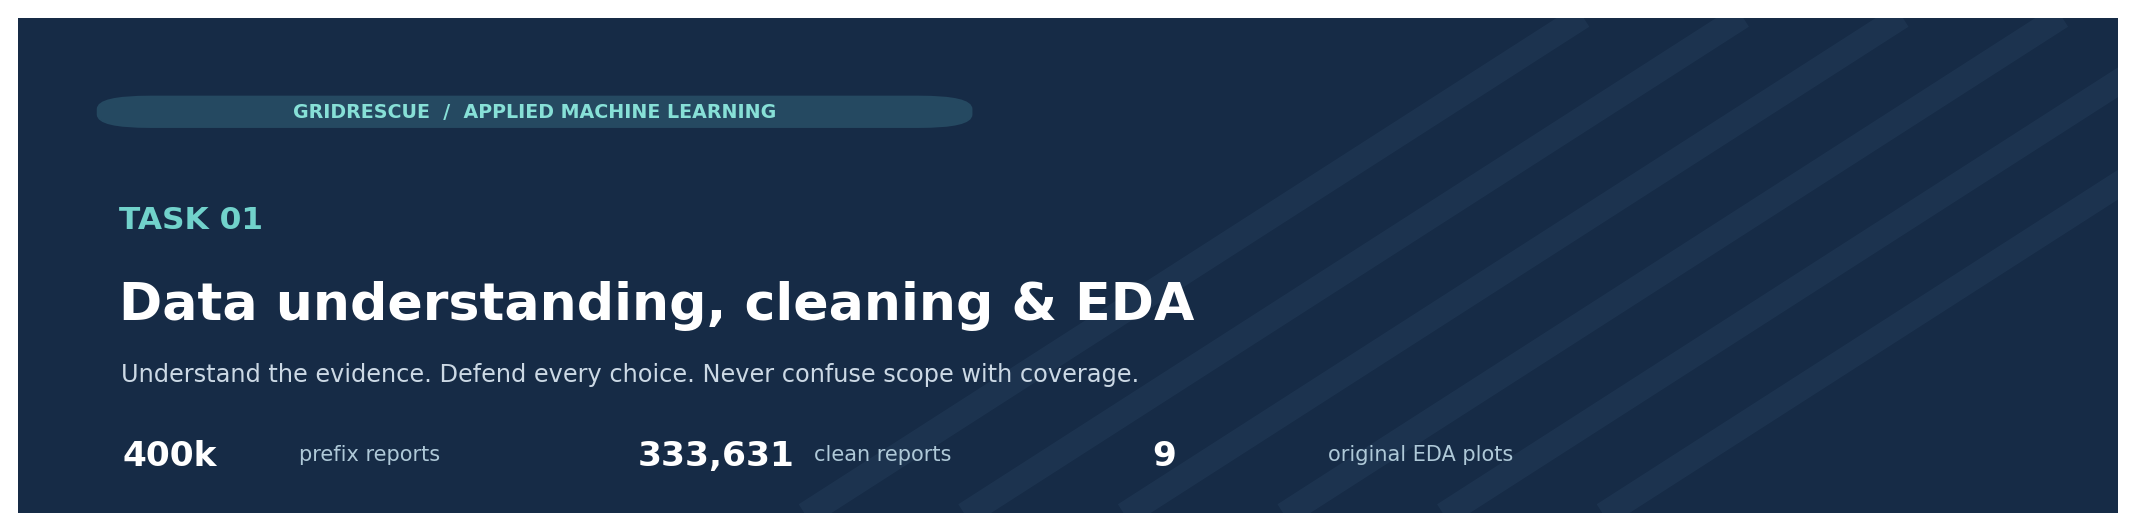

*GridRescue · saved executed results · project-specific scope limitations apply*

# GridRescue · Task 01 — Data Understanding, Cleaning & EDA

> **Scope:** EDA and preprocessing use 2018–2021 development data. The 2022 holdout stays sealed.

**Research question:** Given a U.S. county's currently reported outage count and prior measurements, can we classify whether reported customers without power increase substantially in the next three hours?

**Exact research target:** `y=1` if the maximum of **12 complete future 15-minute observations** reaches `current + max(200, 0.5 × current)`; otherwise `y=0` only when the window is complete. Current count must be positive. We never label unobserved future slots as zero.

**Scientific safeguards:** 2018–2020 training; 2021 validation; 2022 final holdout sealed; historical past-only features; three-hour horizon purge. This is **conditional historical outage escalation research**, not a real-time warning product.

**Intended users:** Students and preparedness analysts reviewing historical reporting patterns. A future application could accept a valid county history, show an escalation score and explain which inputs influence it. Development success is measured against class prevalence and simpler baselines in Task 3.

### Navigate directly to a section

| Jump to section | Focus |
|---|---|
| [01 · Data understanding](#task1-understanding) | Source schema, sampling, row counts and target coverage |
| [02 · Data cleaning](#task1-cleaning) | Quarantine, duplicate/invalid audit and IQR outliers |
| [03 · Exploratory data analysis](#task1-eda) | Nine original plots, grouped summaries and feature relationships |
| [03A · Multicollinearity and unusual patterns](#task1-vif) | Development-only VIF and engineering identity checks |
| [03B · Three evidence-based findings](#task1-three-findings) | Data-generated interpretations, not invented results |
| [04 · Findings and limitations](#task1-findings) | Final reconciliation and research constraints |

### Understand the four data scopes

| Data scope | Which observations? | Why we use it |
|---|---|---|
| **Original EAGLE-I source** | 2018–2022, 122,019,012 data records plus five headers in the audited file inventory | Data provenance and scale; 2022 is sealed for final ML assessment |
| **Full development-source integrity audit** | 2018–2021, 96,222,547 parsed records | Spark schema, null and invalid-token checks before nationwide deduplication |
| **January-prefix sample** | First 100,000 source rows in each 2018–2021 year; 400,000 January raw rows | Detailed reproducible Spark, EDA and preprocessing examples; **not** nationally representative |
| **Full-year three-county development cohort** | Los Angeles (06037), Miami-Dade (12086), Harris (48201), 2018–2021 | Separate primary modeling population, all months represented in available observations; **not** nationally representative |

**Do not concatenate the January and county cohorts:** their source rows overlap. "All months represented" never means that every 15-minute county-time slot is observed. The 2022 modeling holdout is not loaded in these notebooks.

**Reading the code:** Small Spark sections explain **what → how → output → why it matters**. Reusable functions remain in `src/gridrescue/`; they are not silently reimplemented in the notebook.


## Dataset provenance, license, and measurable scope

- **Origin:** Oak Ridge National Laboratory (ORNL), EAGLE-I reported electricity-outage estimates, collected from public utility outage maps, commonly at approximately 15-minute intervals. Original archive: [Figshare DOI 10.6084/m9.figshare.24237376](https://doi.org/10.6084/m9.figshare.24237376); scientific data descriptor: [Scientific Data 2024](https://doi.org/10.1038/s41597-024-03095-5).
- **Reuse license:** The [published Figshare record](https://doi.org/10.6084/m9.figshare.24237376) lists **CC BY 4.0**. The exact archive revision behind the local CSVs remains unverified.
- **Raw columns:** `fips_code`, `county`, `state`, `customers_out`, `run_start_time`. The county code is a five-character **identifier**, not a number. Geographic names are descriptive labels, not personal information.
- **Known limits:** Utility-reported measurements may be missing, stale or inaccurate; rows omitted from the archive may represent zeros or reporting gaps; 15-minute observations of the same customer are **not independent outage events**. Reporting coverage varies across locations and dates.
- **Measured scopes (kept separate):** 122,019,012 parsed source records plus five headers across 2018–2022; 96,222,547 of these in the 2018–2021 development source integrity audit; the deterministic **400k January-prefix development** cohort; and the **418,374-row three-county development** cohort used for the fuller seasonal ML design. Only the latter selected cohorts have been fully cleaned/featured. The full source count does **not** imply full national Silver/Gold processing.
- **Success means:** defensible data-quality accounting, at least three meaningful EDA findings, leakage-safe features, later a fair three-model comparison, and a reproducible inference application. An operational prediction-accuracy threshold is **not asserted** without validation.

In [1]:
from pathlib import Path
import sys, json, os
# Search upward so this works from the project root or notebooks folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/gridrescue/pipeline.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from the GridRescue repository.')
sys.path.insert(0, str(ROOT / 'src'))
from gridrescue.pipeline import make_spark, read_source, clean, features, audit_labels, fit_preparation, PREDICTORS, SOURCE
from pyspark.sql import functions as F, Window
from gridrescue.storage import read_frame,load_preparation,scope_paths
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
# Start a local Spark session with UTC timestamps.
spark = make_spark('GridRescue coursework')
BASE = ROOT / 'artifacts/sample'
SILVER = ROOT / 'data/silver/sample'
GOLD = ROOT / 'data/gold/sample/features'
LABELS = ROOT / 'data/gold/sample/label_audit'
MODE = os.environ.get('GRIDRESCUE_STORAGE_MODE','arrow-local' if os.name=='nt' else 'parquet')
if MODE not in ['memory','parquet','arrow-local']:
    raise ValueError('GRIDRESCUE_STORAGE_MODE must be memory, parquet or arrow-local')
# Resolve the sample paths for the chosen storage backend.
LOCATIONS=scope_paths(ROOT,'sample','arrow-local' if MODE=='arrow-local' else 'native')
BASE=LOCATIONS['artifacts']; SILVER=LOCATIONS['silver']; GOLD=LOCATIONS['gold']; LABELS=LOCATIONS['label_audit']
AUDIT_PATH = ROOT/'reports/memory/sample/audit.json' if MODE=='memory' else LOCATIONS['report']/'audit.json'
required = [AUDIT_PATH] + ([SILVER,GOLD,LABELS] if MODE!='memory' else [])
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise RuntimeError('Run scripts/make_sample.py then scripts/run_pipeline.py first. Missing: ' + ', '.join(missing))
audit = json.loads(AUDIT_PATH.read_text(encoding='utf-8-sig'))
manifest = json.loads((ROOT / 'reports/source_manifest.json').read_text(encoding='utf-8-sig'))
sample_manifest = json.loads((ROOT / 'reports/sample_manifest.json').read_text(encoding='utf-8-sig'))
if MODE=='memory':
    raw = read_source(spark,sorted((ROOT/'data/sample').glob('*.csv'))).cache()
    silver, quarantine, live_counts = clean(raw)
    assert live_counts==audit['counts']
    gold = features(silver).cache()
    labels = audit_labels(gold).cache()
else:
    silver = read_frame(spark,SILVER)
    gold = read_frame(spark,GOLD)
    labels = read_frame(spark,LABELS)
print('Execution mode:',MODE,'; persistence is verified separately by scripts/preflight.py.')
print('SCOPE: first 100,000 actual rows per development year 2018-2021; not representative.')
print('No 2022 records are loaded for EDA, feature selection, label decisions or fitting.')
print('Three-county experimental target conditionally approved; this notebook performs no supervised training.')
print('Spark:', spark.version, 'Timezone:', spark.conf.get('spark.sql.session.timeZone'))



import pandas as pd,inspect
from IPython.display import Code
from pyspark.sql.types import TimestampType
pd.set_option('display.max_rows',20)
pd.set_option('display.max_columns',16)
pd.set_option('display.float_format',lambda value:f'{value:,.3f}')

# High-contrast DataFrame rendering for both VS Code dark and light themes.
# This changes HTML display only; Spark processing and numeric results are untouched.
import re as _gr_re

def _gr_style_dataframe_html(source):
    """Return readable notebook HTML for a pandas table, or pass other HTML through."""
    if not source or '<table' not in source or 'dataframe' not in source:
        return source
    if 'data-gridrescue-theme=' in source:
        return source

    source = _gr_re.sub(
        r'<table\b([^>]*)>',
        lambda m: '<table' + m.group(1) +
                  ' data-gridrescue-theme="high-contrast" style="border-collapse:collapse !important; '
                  'background:#142334 !important; color:#eef5ff !important; width:100% !important; '
                  'font-size:13px !important; line-height:1.48 !important;">',
        source, count=1,
    )

    def _cells(section, header=False):
        """Color this HTML cell group, using teal for headings and navy for data."""
        def _paint(match):
            """Render one HTML table cell with a contrasting font color."""
            tag, attrs = match.group(1), match.group(2)
            if header:
                color = '#e5f9f6'
                bg = '#164654'
                weight = '700'
            else:
                bg = section['bg']
                color = '#96ddd5' if tag == 'th' else '#eef5ff'
                weight = '600' if tag == 'th' else '400'
            style = (
                'background-color:' + bg + ' !important; '
                'color:' + color + ' !important; '
                'border-bottom:1px solid #31495e !important; '
                'padding:8px 12px !important; '
                'text-align:left !important; vertical-align:top !important; '
                'white-space:normal !important; overflow-wrap:anywhere !important; '
                'font-weight:' + weight + ' !important;'
            )
            # Pandas may add inline attributes to header/index cells.
            attrs = _gr_re.sub(r'\sstyle\s*=\s*(["\']).*?\1', '', attrs, flags=_gr_re.S)
            return '<' + tag + attrs + ' style="' + style + '">'
        return _gr_re.sub(r'<(th|td)\b([^>]*)>', _paint, section['body'], flags=_gr_re.I)

    def _paint_head(match):
        """Return the heading section with the fixed teal style."""
        section = {'bg':'#164654','body':match.group(2)}
        return match.group(1) + _cells(section, header=True) + match.group(3)

    def _paint_body(match):
        """Return the data section with alternating navy rows."""
        body = match.group(2)
        num = [0]
        def _row(row):
            """Color one data row and advance the stripe counter."""
            color = '#1c3045' if num[0] % 2 == 0 else '#142638'
            num[0] += 1
            return _cells({'bg':color,'body':row.group(0)})
        body = _gr_re.sub(r'<tr\b[^>]*>.*?</tr>', _row, body, flags=_gr_re.S|_gr_re.I)
        return match.group(1) + body + match.group(3)

    source = _gr_re.sub(r'(<thead\b[^>]*>)(.*?)(</thead>)', _paint_head, source, flags=_gr_re.S|_gr_re.I)
    source = _gr_re.sub(r'(<tbody\b[^>]*>)(.*?)(</tbody>)', _paint_body, source, flags=_gr_re.S|_gr_re.I)
    return source

# Register an explicit formatter: display(df) and display(SparkFrame.toPandas())
# remain readable after re-execution, without modifying each analysis cell.
get_ipython().display_formatter.formatters['text/html'].for_type(
    pd.DataFrame, lambda frame: _gr_style_dataframe_html(frame._repr_html_())
)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi':110,'axes.titlesize':11,'axes.labelsize':10,
                     'axes.spines.top':False,'axes.spines.right':False,'figure.autolayout':True})
def show_table(frame,rows=10,scope=None):
    """Display a bounded Spark table and its scope with readable UTC timestamps."""
    # limit() bounds the rows before collecting them into pandas.
    bounded=frame.limit(rows)
    for field in bounded.schema:
        if isinstance(field.dataType,TimestampType):
            bounded=bounded.withColumn(field.name,F.date_format(field.name,'yyyy-MM-dd HH:mm:ss'))
    display(Markdown(f'*Scope: {scope or SCOPE_LABEL}; up to {rows} displayed rows.*'))
    display(bounded.toPandas())
SCOPE_LABEL=f"Prefix: {audit['counts']['raw']:,} raw rows, 2018–2021"

county_scope_path=ROOT/'reports/memory/county/audit.json' if MODE=='memory' else scope_paths(ROOT,'county','arrow-local' if MODE=='arrow-local' else 'native')['report']/'audit.json'
county_scope_audit=json.loads(county_scope_path.read_text())
display(pd.DataFrame([{'scope':label,'raw reports':item['counts']['raw'],'Silver rows':item['counts']['silver'],
    'eligible preparation rows':sum(r['count'] for r in item['eligible_preparation_counts'])}
    for label,item in [('January prefix — main worked examples',audit),('Three counties — separate full-year cohort',county_scope_audit)]]))
print('The two cohorts are not combined. Current preparation/scaling examples use the prefix unless labeled three-county.')

Execution mode: arrow-local ; persistence is verified separately by scripts/preflight.py.
SCOPE: first 100,000 actual rows per development year 2018-2021; not representative.
No 2022 records are loaded for EDA, feature selection, label decisions or fitting.
Three-county experimental target conditionally approved; this notebook performs no supervised training.
Spark: 3.5.3 Timezone: UTC


scope  raw reports  Silver rows  \
0       January prefix — main worked examples       400000       333631   
1  Three counties — separate full-year cohort       418374       416940   

   eligible preparation rows  
0                     163386  
1                     406240

The two cohorts are not combined. Current preparation/scaling examples use the prefix unless labeled three-county.


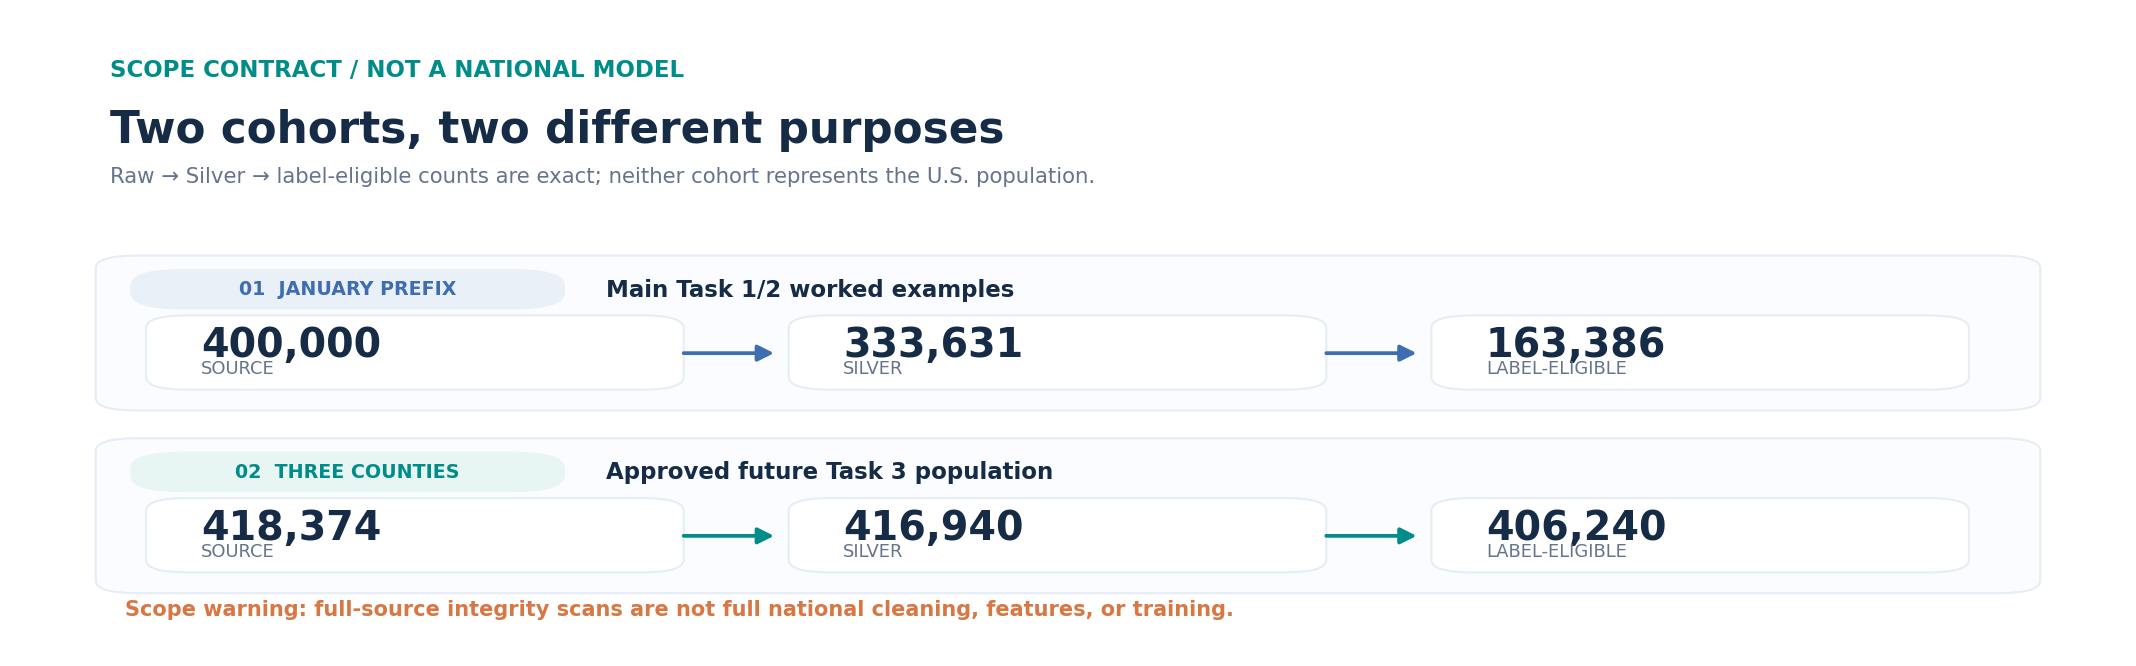

*Measured scope reconciliation: each cohort is processed independently.*

<a id="task1-understanding"></a>
## 01 Data Understanding
### Read Data
Read source tokens as strings before parsing: this preserves leading-zero FIPS and invalid
measurement tokens. The actual source column is `customers_out`, not the planned name `sum`.

**What / why:** Inspect the original five string columns and actual raw reports. Parsing after inspection preserves invalid tokens and leading-zero county identifiers.

**How:** read_source supplies a schema and header validation; cache stores reused partitions after an action materializes them.

**Implementation:** `src/gridrescue/pipeline.py: read_source`.

In [2]:
# Find only the deterministic development CSV prefixes.
sample_paths = sorted((ROOT / 'data/sample').glob('eaglei_outages_*.csv'))
assert sample_paths and all('2022' not in p.name for p in sample_paths)
# Read five original string columns and cache the rows for repeated EDA.
raw = read_source(spark, sample_paths).cache()
# Print Spark types before any cleaning or numeric conversion.
raw.printSchema()
show_table(raw,5)

root
 |-- fips_code: string (nullable = true)
 |-- county: string (nullable = true)
 |-- state: string (nullable = true)
 |-- customers_out: string (nullable = true)
 |-- run_start_time: string (nullable = true)



*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 5 displayed rows.*

fips_code    county    state customers_out       run_start_time
0     01003   Baldwin  Alabama             6  2021-01-01 00:00:00
1     01009    Blount  Alabama             4  2021-01-01 00:00:00
2     01017  Chambers  Alabama             4  2021-01-01 00:00:00
3     01031    Coffee  Alabama             1  2021-01-01 00:00:00
4     01051    Elmore  Alabama             4  2021-01-01 00:00:00

### Random Sample Data
A seeded random display within the prefix subset is not a random population sample.
Prefix truncation creates artificial final-window gaps; conclusions cannot be generalized to all seasons.

**What / why:** Display a reproducible random selection inside the prefix. A few rows help us recognize the data without collecting the dataset.

**How:** rand(seed=17) orders this bounded development subset; show returns only ten rows. Random display does not remove prefix selection bias.

**Implementation:** `Spark rand/orderBy in the cell below`.

In [3]:
# Assign a seeded random key, sort by it, then show just ten rows.
show_table(raw.orderBy(F.rand(seed=17)),10)

*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 10 displayed rows.*

fips_code    county          state customers_out       run_start_time
0     13239   Quitman        Georgia             3  2019-01-02 15:15:00
1     36047     Kings       New York           225  2021-01-02 01:45:00
2     17139  Moultrie       Illinois            38  2021-01-01 19:00:00
3     36071    Orange       New York             2  2018-01-01 03:30:00
4     33001   Belknap  New Hampshire            12  2018-01-02 01:45:00
5     47059    Greene      Tennessee             1  2021-01-01 15:15:00
6     18011     Boone        Indiana          None  2020-01-02 00:30:00
7     29105   Laclede       Missouri             1  2020-01-01 12:00:00
8     17027   Clinton       Illinois             1  2021-01-02 01:15:00
9     39103    Medina           Ohio           142  2019-01-01 15:30:00

### Size of Data (Shape)
Distinguish parsed sample rows from full-file physical record counts. The manifest's physical
counts are independently parsed records. Complete development Spark integrity counts are
recorded separately in `reports/full_development_audit.json`; full-source deduplication is not claimed.

**What / why:** Compare raw and clean subset sizes with original source inventory. The full-source audit, January prefix and full-year counties answer different questions.

**How:** count is a Spark action. Inventory is previously verified metadata; displaying the 2022 integrity count does not load its observations.

**Implementation:** `reports/source_manifest.json and reports/sample_manifest.json`.

In [4]:
# count() scans the rows. len(columns) counts the schema fields.
print('Parsed raw subset shape:', (raw.count(), len(raw.columns)))
# count() scans the rows. len(columns) counts the schema fields.
print('Clean subset shape:', (silver.count(), len(silver.columns)))
# Pick only inventory fields needed for the comparison.
file_rows = [{k: f.get(k) for k in ['path','bytes','physical_data_lines','row_count','status']}
             for f in manifest['files']]
display(pd.DataFrame(file_rows))
display(pd.DataFrame(sample_manifest)[['year','rows','method']])

Parsed raw subset shape: (400000, 5)


Clean subset shape: (333631, 6)


path       bytes  physical_data_lines  \
0  data/raw/eaglei_outages_2018.csv   999210542             21776806   
1  data/raw/eaglei_outages_2019.csv  1102778792             24074122   
2  data/raw/eaglei_outages_2020.csv  1170699724             25545517   
3  data/raw/eaglei_outages_2021.csv  1141058232             24826102   
4  data/raw/eaglei_outages_2022.csv  1187596176             25796465   

   row_count  \
0   21776806   
1   24074122   
2   25545517   
3   24826102   
4   25796465   

                                                                                     status  
0  VERIFIED Python csv record count and original byte hash; Spark count recorded separately  
1  VERIFIED Python csv record count and original byte hash; Spark count recorded separately  
2  VERIFIED Python csv record count and original byte hash; Spark count recorded separately  
3  VERIFIED Python csv record count and original byte hash; Spark count recorded separately  
4  VERIFIED Python csv record count and original byte hash; Spark count recorded separately

year    rows  \
0  2018  100000   
1  2019  100000   
2  2020  100000   
3  2021  100000   

                                                                               method  
0  first 100000 source observations; contiguous prefix; not population representative  
1  first 100000 source observations; contiguous prefix; not population representative  
2  first 100000 source observations; contiguous prefix; not population representative  
3  first 100000 source observations; contiguous prefix; not population representative

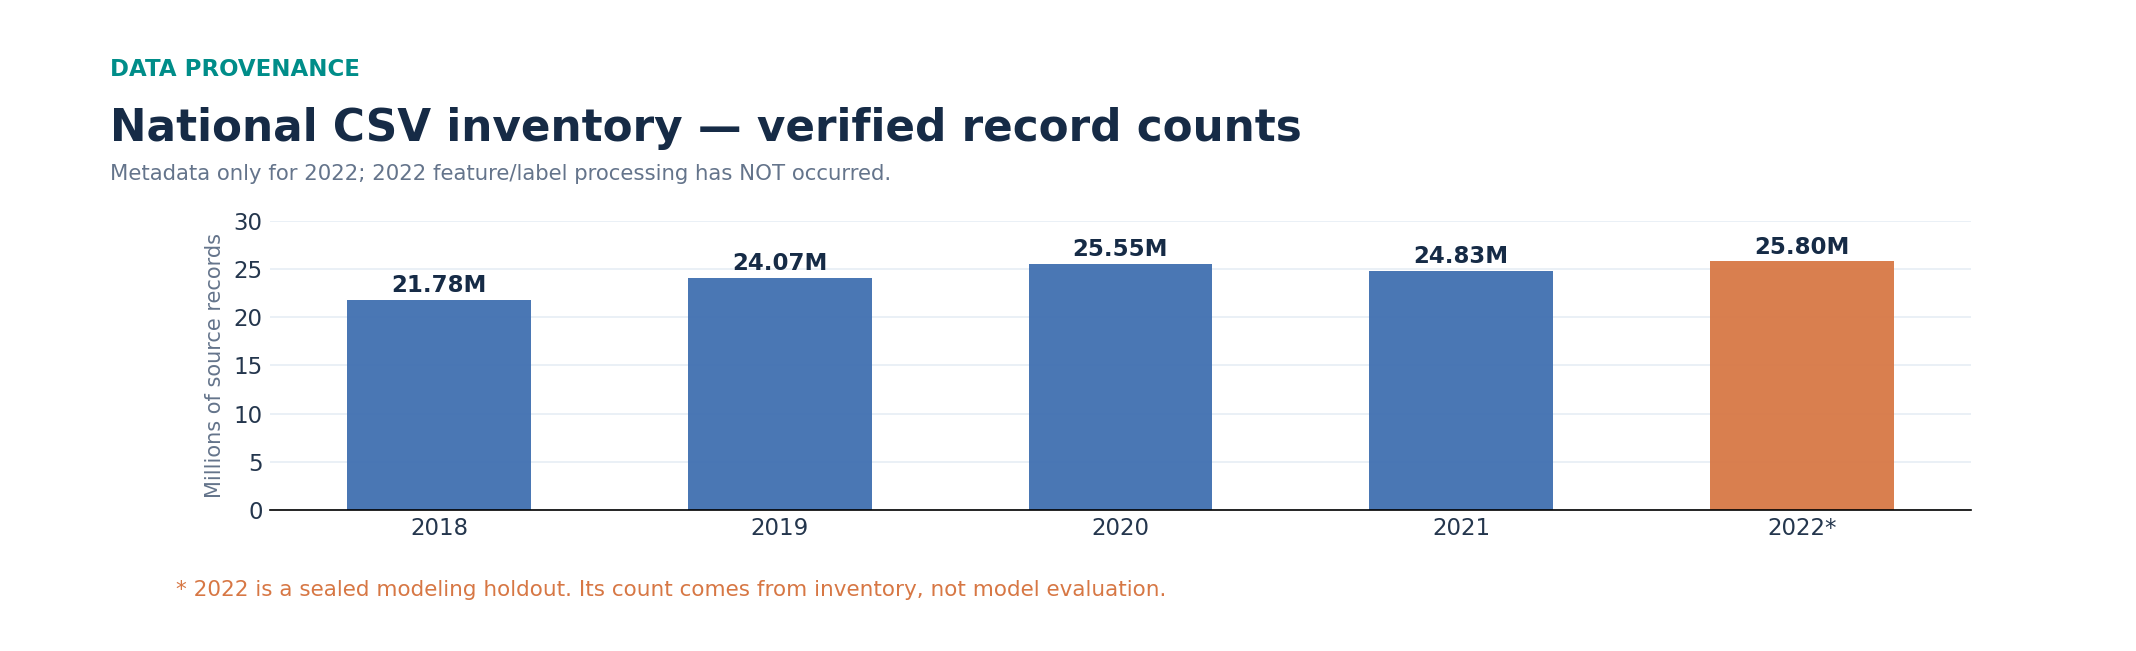

*Original CSV counts; 2022 is inventory-only, not an evaluated modeling year.*

### Source coverage and the scope ledger

**What/why:** reconcile original parsed counts and distinguish the three populations. **How:** read existing measured audit metadata, with no new raw-source scan. **Where:** reports/full_development_audit.json; memory/county/audit.json.

In [5]:
full_audit=json.loads((ROOT/'reports/full_development_audit.json').read_text())
assert full_audit['status']=='VERIFIED_FULL_DEVELOPMENT_INTEGRITY_ONLY'
full_rows=pd.DataFrame([{key:item[key] for key in ['year','parsed_rows','invalid_rows_any_reason',
    'null_customers_out','off_grid_timestamp','valid_rows_before_deduplication',
    'min_parsed_timestamp_utc','max_parsed_timestamp_utc']} for item in full_audit['files']])
display(full_rows)
county_audit=county_scope_audit
scope_rows=[{'scope':'Complete development sources — integrity audit only','raw_records':int(full_rows.parsed_rows.sum()),
             'invalid_any_reason':int(full_rows.invalid_rows_any_reason.sum()),'Silver_after_dedup':'Not established nationally'},
            {'scope':'January prefixes — cleaning + EDA','raw_records':audit['counts']['raw'],
             'invalid_any_reason':audit['counts']['invalid'],'Silver_after_dedup':audit['counts']['silver']},
            {'scope':'Three counties — full development dates','raw_records':county_audit['counts']['raw'],
             'invalid_any_reason':county_audit['counts']['invalid'],'Silver_after_dedup':county_audit['counts']['silver']}]
display(pd.DataFrame(scope_rows))
parsed_total=sum(item['row_count'] for item in manifest['files'])
display(Markdown(f"**Inventory reconciliation:** {parsed_total:,} parsed data records + {len(manifest['files'])} headers = {parsed_total+len(manifest['files']):,}. This exactly reconciles the supplied total; the source author's counting method was not independently verified. The 2022 number is existing integrity metadata only."))
display(Markdown('**Coverage:** every full source year ends at December 31 00:00 UTC, leaving the rest of that calendar day unobserved. Prefixes cover January only; the fixed counties cover all twelve months. Full-source duplicate, feature and label results have not been computed nationally.'))

year  parsed_rows  invalid_rows_any_reason  null_customers_out  \
0  2018     21776806                  2041717             2027828   
1  2019     24074122                  1366776             1366771   
2  2020     25545517                  2105233             2101520   
3  2021     24826102                  1105095             1104738   

   off_grid_timestamp  valid_rows_before_deduplication  \
0               15473                         19735089   
1                 132                         22707346   
2                3747                         23440284   
3                 498                         23721007   

  min_parsed_timestamp_utc max_parsed_timestamp_utc  
0      2018-01-01 00:00:00      2018-12-31 00:00:00  
1      2019-01-01 00:00:00      2019-12-31 00:00:00  
2      2020-01-01 00:00:00      2020-12-31 00:00:00  
3      2021-01-01 00:00:00      2021-12-31 00:00:00

scope  raw_records  \
0  Complete development sources — integrity audit only     96222547   
1                    January prefixes — cleaning + EDA       400000   
2              Three counties — full development dates       418374   

   invalid_any_reason          Silver_after_dedup  
0             6618821  Not established nationally  
1               66369                      333631  
2                1434                      416940

**Inventory reconciliation:** 122,019,012 parsed data records + 5 headers = 122,019,017. This exactly reconciles the supplied total; the source author's counting method was not independently verified. The 2022 number is existing integrity metadata only.

**Coverage:** every full source year ends at December 31 00:00 UTC, leaving the rest of that calendar day unobserved. Prefixes cover January only; the fixed counties cover all twelve months. Full-source duplicate, feature and label results have not been computed nationally.

### Information of Data — Types, Non-null Counts, Memory
Storage bytes, cached Spark blocks, Python-process RSS and a bounded pandas frame measure different
things. Spark reports allocated cached-block memory for this local executor at this instant; it is not
peak cluster RAM or the memory required for the entire source. Python RSS excludes the JVM. The small
pandas frame includes deep object storage, but must not be extrapolated to 122 million records.

**What / why:** Inspect schemas, non-null counts and several distinct memory measurements. File bytes, Python RAM and Spark cache allocation are different quantities.

**How:** count(column) ignores nulls. Only 1,000 rows enter pandas for display/memory measurement; the full Spark data remains distributed.

**Implementation:** `Spark aggregation; psutil; reports/memory_usage.json`.

In [6]:
# Print the types after parsing UTC timestamps and outage counts.
silver.printSchema()
raw.select(*[F.count(c).alias(c + '_nonnull') for c in raw.columns]).show(truncate=False)
silver.select(*[F.count(c).alias(c + '_nonnull') for c in silver.columns]).show(truncate=False)
print('Subset CSV bytes:', sum(p.stat().st_size for p in sample_paths))
print('Silver Parquet storage bytes:', sum(p.stat().st_size for p in SILVER.rglob('*.parquet')))
import psutil
# Collect at most 1,000 records before measuring pandas memory.
bounded_frame=raw.limit(1000).toPandas()
# Look up Spark cache allocations separately from the Python process.
cache_info=spark.sparkContext._jsc.sc().getRDDStorageInfo()
memory={'mode':MODE,'python_driver_rss_bytes':psutil.Process().memory_info().rss,
        'spark_cached_block_bytes':sum(int(info.memSize()) for info in cache_info),
        'spark_cached_disk_bytes':sum(int(info.diskSize()) for info in cache_info),
        'bounded_pandas_rows':len(bounded_frame),
        'bounded_pandas_deep_bytes':int(bounded_frame.memory_usage(index=True,deep=True).sum()),
        'scope':'Instantaneous local cache allocation and Python RSS; not peak JVM/cluster RAM or whole-source memory'}
(ROOT/'reports/memory_usage.json').write_text(json.dumps(memory,indent=2),encoding='utf-8')
display(memory)

root
 |-- fips_code: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- county: string (nullable = true)
 |-- state: string (nullable = true)
 |-- run_start_time: string (nullable = true)
 |-- customers_out: long (nullable = true)



+-----------------+--------------+-------------+---------------------+----------------------+
|fips_code_nonnull|county_nonnull|state_nonnull|customers_out_nonnull|run_start_time_nonnull|
+-----------------+--------------+-------------+---------------------+----------------------+
|400000           |400000        |400000       |333631               |400000                |
+-----------------+--------------+-------------+---------------------+----------------------+



+-----------------+-----------------+--------------+-------------+----------------------+---------------------+
|fips_code_nonnull|timestamp_nonnull|county_nonnull|state_nonnull|run_start_time_nonnull|customers_out_nonnull|
+-----------------+-----------------+--------------+-------------+----------------------+---------------------+
|333631           |333631           |333631        |333631       |333631                |333631               |
+-----------------+-----------------+--------------+-------------+----------------------+---------------------+

Subset CSV bytes: 18755115
Silver Parquet storage bytes: 3759630


{'mode': 'arrow-local',
 'python_driver_rss_bytes': 173744128,
 'spark_cached_block_bytes': 3968840,
 'spark_cached_disk_bytes': 0,
 'bounded_pandas_rows': 1000,
 'bounded_pandas_deep_bytes': 283960,
 'scope': 'Instantaneous local cache allocation and Python RSS; not peak JVM/cluster RAM or whole-source memory'}

### Check Names of Columns
`fips_code`: five-character county identifier; `county`/`state`: geographic labels;
`customers_out`: reported count of customers without electricity, not kWh;
`run_start_time`: source UTC observation text, parsed to `timestamp` in Silver.
One row is a county-time report, not one independent outage event.

**What / why:** Name and explain each source column. A customer count is neither energy consumption nor a count of independent outages.

**How:** Source names are preserved; Silver adds a typed UTC timestamp and numeric count.

**Implementation:** `pipeline.SOURCE and pipeline.clean`.

In [7]:
print('Source columns:', raw.columns)
print('Silver columns:', silver.columns)

Source columns: ['fips_code', 'county', 'state', 'customers_out', 'run_start_time']
Silver columns: ['fips_code', 'timestamp', 'county', 'state', 'run_start_time', 'customers_out']


### Check Description

**What / why:** Summarize outage size and observed date coverage. The prefix cannot support claims about an entire year or national reporting completeness.

**How:** describe and min/max/groupBy are Spark aggregations over the explicit prefix scope.

**Implementation:** `Spark DataFrame.describe and groupBy/agg`.

In [8]:
# Select the numeric Spark column and compute basic summary statistics.
silver.select('customers_out').describe().show()
silver.agg(F.min('timestamp').alias('earliest'), F.max('timestamp').alias('latest'),
           F.countDistinct('fips_code').alias('counties'), F.countDistinct('state').alias('states')).show()
silver.groupBy(F.year('timestamp').alias('year')).agg(F.min('timestamp').alias('first'),
        F.max('timestamp').alias('last'), F.count('*').alias('rows')).orderBy('year').show()

+-------+------------------+
|summary|     customers_out|
+-------+------------------+
|  count|            333631|
|   mean|117.21585823859294|
| stddev|  591.136409568814|
|    min|                 1|
|    max|             22952|
+-------+------------------+



+-------------------+-------------------+--------+------+
|           earliest|             latest|counties|states|
+-------------------+-------------------+--------+------+
|2018-01-01 00:00:00|2021-01-02 17:45:00|    2636|    53|
+-------------------+-------------------+--------+------+



+----+-------------------+-------------------+-----+
|year|              first|               last| rows|
+----+-------------------+-------------------+-----+
|2018|2018-01-01 00:00:00|2018-01-02 20:00:00|91529|
|2019|2019-01-01 00:00:00|2019-01-02 15:15:00|80971|
|2020|2020-01-01 00:00:00|2020-01-02 15:15:00|62513|
|2021|2021-01-01 00:00:00|2021-01-02 17:45:00|98618|
+----+-------------------+-------------------+-----+



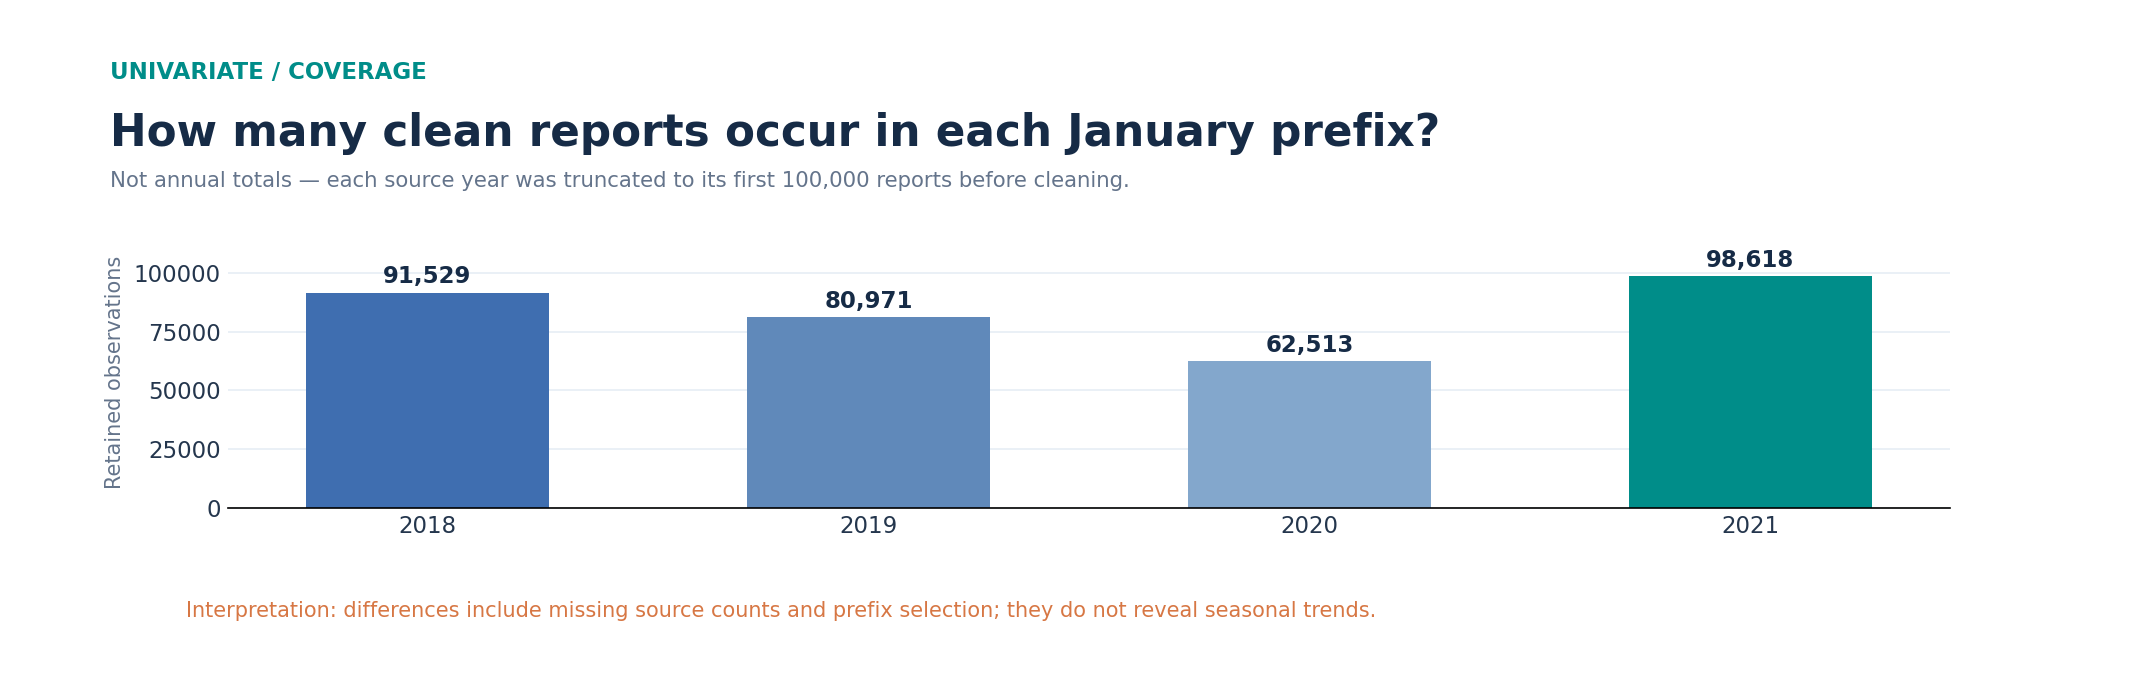

*Clean observed counts by prefix year, not total-year reporting or seasonality.*

### Number of Unique Values
Count each source column. High cardinality in IDs and timestamps is expected; FIPS magnitude
has no meaningful numerical relationship with outage severity.

**What / why:** Count distinct non-null values in each original column. Identifiers and timestamps naturally have high cardinality; ID magnitude is not a severity feature.

**How:** countDistinct is an aggregation that reduces rows to compact summary values.

**Implementation:** `Spark countDistinct`.

In [9]:
# Build one countDistinct expression for each raw column and aggregate in Spark.
raw.agg(*[F.countDistinct(c).alias(c) for c in raw.columns]).show(truncate=False)

+---------+------+-----+-------------+--------------+
|fips_code|county|state|customers_out|run_start_time|
+---------+------+-----+-------------+--------------+
|2870     |1692  |53   |3839         |660           |
+---------+------+-----+-------------+--------------+



### Check Balance of Data
The fixed three-county target has conditional experimental approval. Report eligible candidate class counts separately from incomplete
outcomes. Do not infer negatives from missing observations or interpret this as model validation.

**What / why:** Separate eligible positives/negatives from incomplete outcomes. Missing future reports cannot be interpreted as negative escalation labels.

**How:** groupBy counts the audited completeness and class combinations; mean of a binary label is prevalence among labeled rows.

**Implementation:** `pipeline.audit_labels and the fixed target approval`.

In [10]:
# Count rows by partition, observed label and future-window completeness.
labels.groupBy('split','candidate_y','label_complete').count().orderBy('split','candidate_y').show(30)
# Retain only rows with observed outcomes in train or validation.
eligible = labels.filter("candidate_y IS NOT NULL AND split IN ('train','validation')")
eligible.agg(F.count('*').alias('eligible_candidates'), F.avg('candidate_y').alias('candidate_positive_prevalence')).show()
print('Conditional scientific approval applies to the fixed three-county experiment; prefix balance is descriptive only.')

+----------+-----------+--------------+------+
|     split|candidate_y|label_complete| count|
+----------+-----------+--------------+------+
|     train|       NULL|         false|125228|
|     train|          0|          true|101583|
|     train|          1|          true|  8202|
|validation|       NULL|         false| 45017|
|validation|          0|          true| 49059|
|validation|          1|          true|  4542|
+----------+-----------+--------------+------+



+-------------------+-----------------------------+
|eligible_candidates|candidate_positive_prevalence|
+-------------------+-----------------------------+
|             163386|          0.07799933898865263|
+-------------------+-----------------------------+

Conditional scientific approval applies to the fixed three-county experiment; prefix balance is descriptive only.


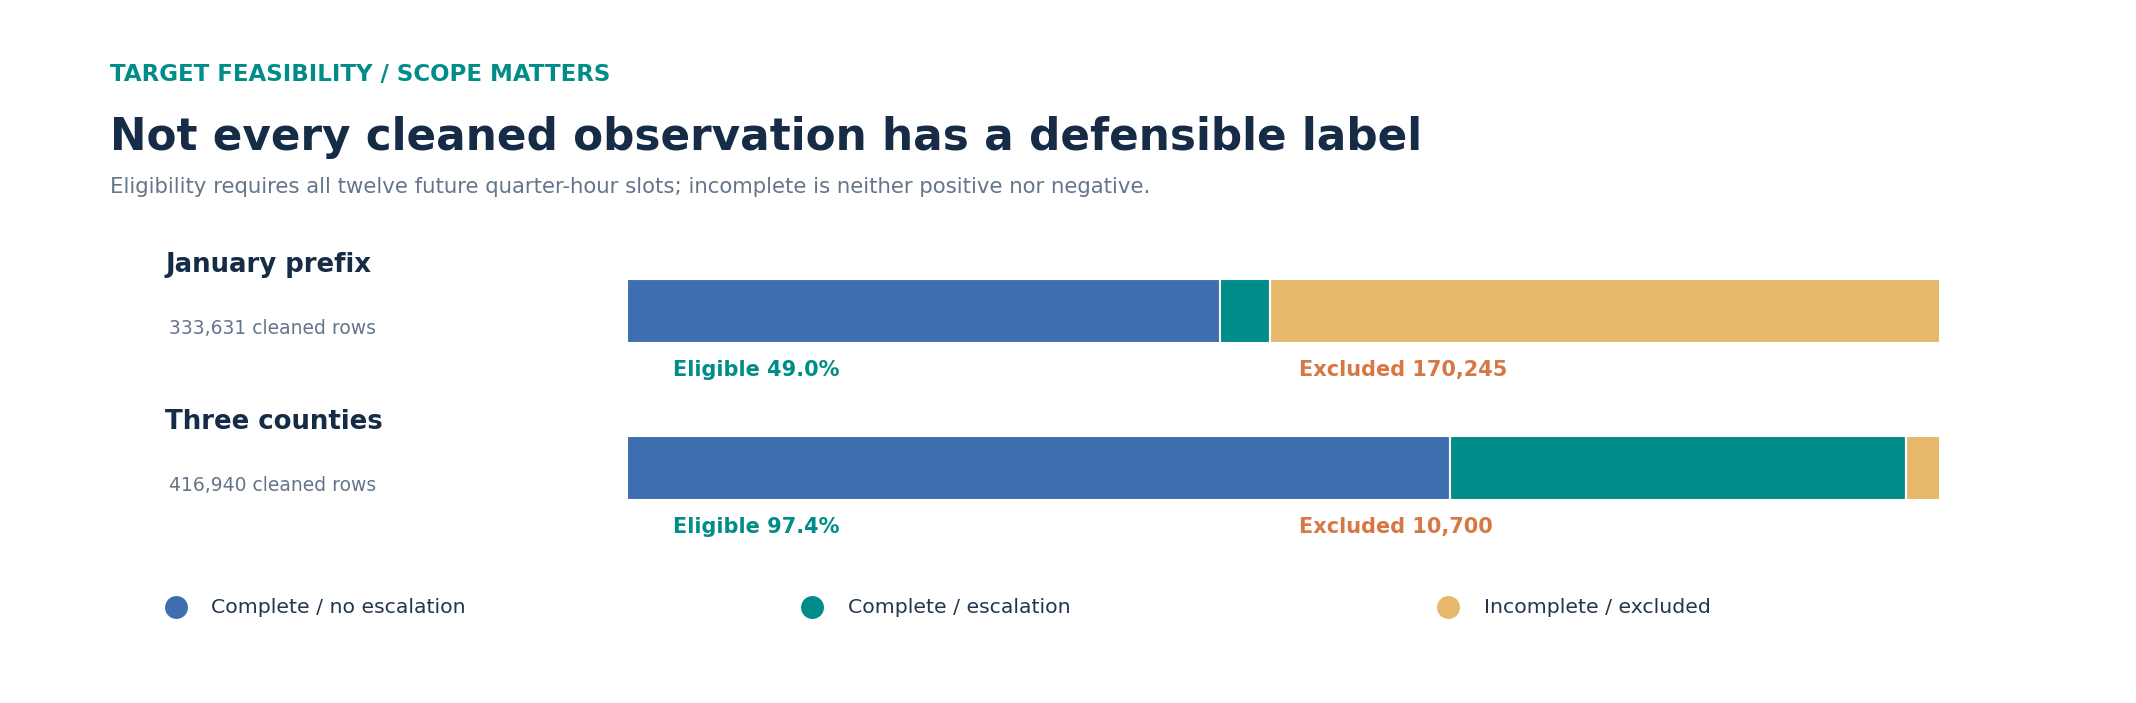

*Label completeness and prevalence are cohort-specific and cannot be compared as national rates.*

<a id="task1-cleaning"></a>
## 02 Data Cleaning
### Missing Values
Nulls are missing values inside existing records. A missing county-time row is an unobserved
interval and may represent zero outages or a reporting gap. Never fill absent rows with zero.
Missing source identity/count/time fields are quarantined, not imputed.

**What / why:** Measure missing tokens, invalid records and internal observation gaps. An unknown count or missing county-time row must never become a fabricated zero.

**How:** isNull flags missing values in existing rows. A county/year ordered window compares neighboring observed timestamps; quarantine stores rejected original tokens and reasons.

**Implementation:** `pipeline.clean; reports/WHAT_CHANGED_IN_DATA.md`.

In [11]:
# Turn each null check into a 0/1 number and sum by column.
raw.agg(*[F.sum(F.col(c).isNull().cast('long')).alias(c) for c in raw.columns]).show()
display({'measured_cleaning_counts': audit.get('counts'), 'source_nulls': audit.get('nulls_raw')})
# Keep counties and years separate, then order observations by UTC time.
w = Window.partitionBy('fips_code',F.year('timestamp')).orderBy('timestamp')
# Apply lag over that window and measure elapsed time between two reported rows.
gaps = (silver.withColumn('previous_timestamp',F.lag('timestamp').over(w))
        .withColumn('elapsed_seconds',F.unix_timestamp('timestamp')-F.unix_timestamp('previous_timestamp'))
        .filter('elapsed_seconds > 900'))
gaps.groupBy(F.year('timestamp').alias('year')).agg(F.count('*').alias('gap_transitions'),
     F.sum(F.col('elapsed_seconds')/900-1).alias('missing_slots_between_observed_endpoints'),
     F.max('elapsed_seconds').alias('longest_gap_seconds')).orderBy('year').show()
print('Gap counts are within county/year observed endpoints; cross-year prefix separations are excluded. Prefix-scope limitations still apply.')

+---------+------+-----+-------------+--------------+
|fips_code|county|state|customers_out|run_start_time|
+---------+------+-----+-------------+--------------+
|        0|     0|    0|        66369|             0|
+---------+------+-----+-------------+--------------+



{'measured_cleaning_counts': {'raw': 400000,
  'invalid': 66369,
  'exact_duplicates_removed': 0,
  'conflict_rows': 0,
  'silver': 333631},
 'source_nulls': {'fips_code': 0,
  'county': 0,
  'state': 0,
  'customers_out': 66369,
  'run_start_time': 0}}

+----+---------------+----------------------------------------+-------------------+
|year|gap_transitions|missing_slots_between_observed_endpoints|longest_gap_seconds|
+----+---------------+----------------------------------------+-------------------+
|2018|           6078|                                115046.0|             156600|
|2019|           3598|                                 78530.0|             140400|
|2020|           3326|                                 80338.0|             137700|
|2021|           4392|                                 93322.0|             144900|
+----+---------------+----------------------------------------+-------------------+

Gap counts are within county/year observed endpoints; cross-year prefix separations are excluded. Prefix-scope limitations still apply.


### Invalid examples and exact cleaning ledger

**What/why:** inspect actual invalid reports and account for every removal. **How:** group quarantine reasons, display six original records and subtract disjoint cleaning categories. **Where:** pipeline.clean and the matching persisted quarantine.

In [12]:
rejected=quarantine if MODE=='memory' else read_frame(spark,LOCATIONS['quarantine'])
print(SCOPE_LABEL,'— real quarantined records')
show_table(rejected.groupBy('reason').count().orderBy(F.desc('count')))
show_table(rejected.select(*SOURCE,'reason').orderBy('run_start_time','fips_code'),6)
counts=audit['counts']
remaining=counts['raw']
cleaning_ledger=[{'stage':'Original parsed reports','removed':0,'remaining':remaining}]
for key,label in [('invalid','Invalid source reports'),('exact_duplicates_removed','Exact valid duplicate copies'),('conflict_rows','Distinct conflicting-key variants')]:
    remaining-=counts[key]
    cleaning_ledger.append({'stage':label,'removed':counts[key],'remaining':remaining})
cleaning_ledger.append({'stage':'Silver retained','removed':0,'remaining':counts['silver']})
display(pd.DataFrame(cleaning_ledger))
assert remaining==counts['silver']
display(Markdown(f"**Finding:** {counts['invalid']:,} invalid reports are excluded, with original tokens and reasons retained in quarantine. Missing outage counts are unknown measurements; substituting zero would invent restoration and distort both past features and future labels."))

Prefix: 400,000 raw rows, 2018–2021 — real quarantined records


*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 10 displayed rows.*

reason  count
0  invalid_count  66369

*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 6 displayed rows.*

fips_code      county       state customers_out       run_start_time  \
0     06061      Placer  California          None  2018-01-01 00:00:00   
1     06067  Sacramento  California          None  2018-01-01 00:00:00   
2     12005         Bay     Florida          None  2018-01-01 00:00:00   
3     12033    Escambia     Florida          None  2018-01-01 00:00:00   
4     12059      Holmes     Florida          None  2018-01-01 00:00:00   
5     12063     Jackson     Florida          None  2018-01-01 00:00:00   

          reason  
0  invalid_count  
1  invalid_count  
2  invalid_count  
3  invalid_count  
4  invalid_count  
5  invalid_count

stage  removed  remaining
0            Original parsed reports        0     400000
1             Invalid source reports    66369     333631
2       Exact valid duplicate copies        0     333631
3  Distinct conflicting-key variants        0     333631
4                    Silver retained        0     333631

**Finding:** 66,369 invalid reports are excluded, with original tokens and reasons retained in quarantine. Missing outage counts are unknown measurements; substituting zero would invent restoration and distort both past features and future labels.

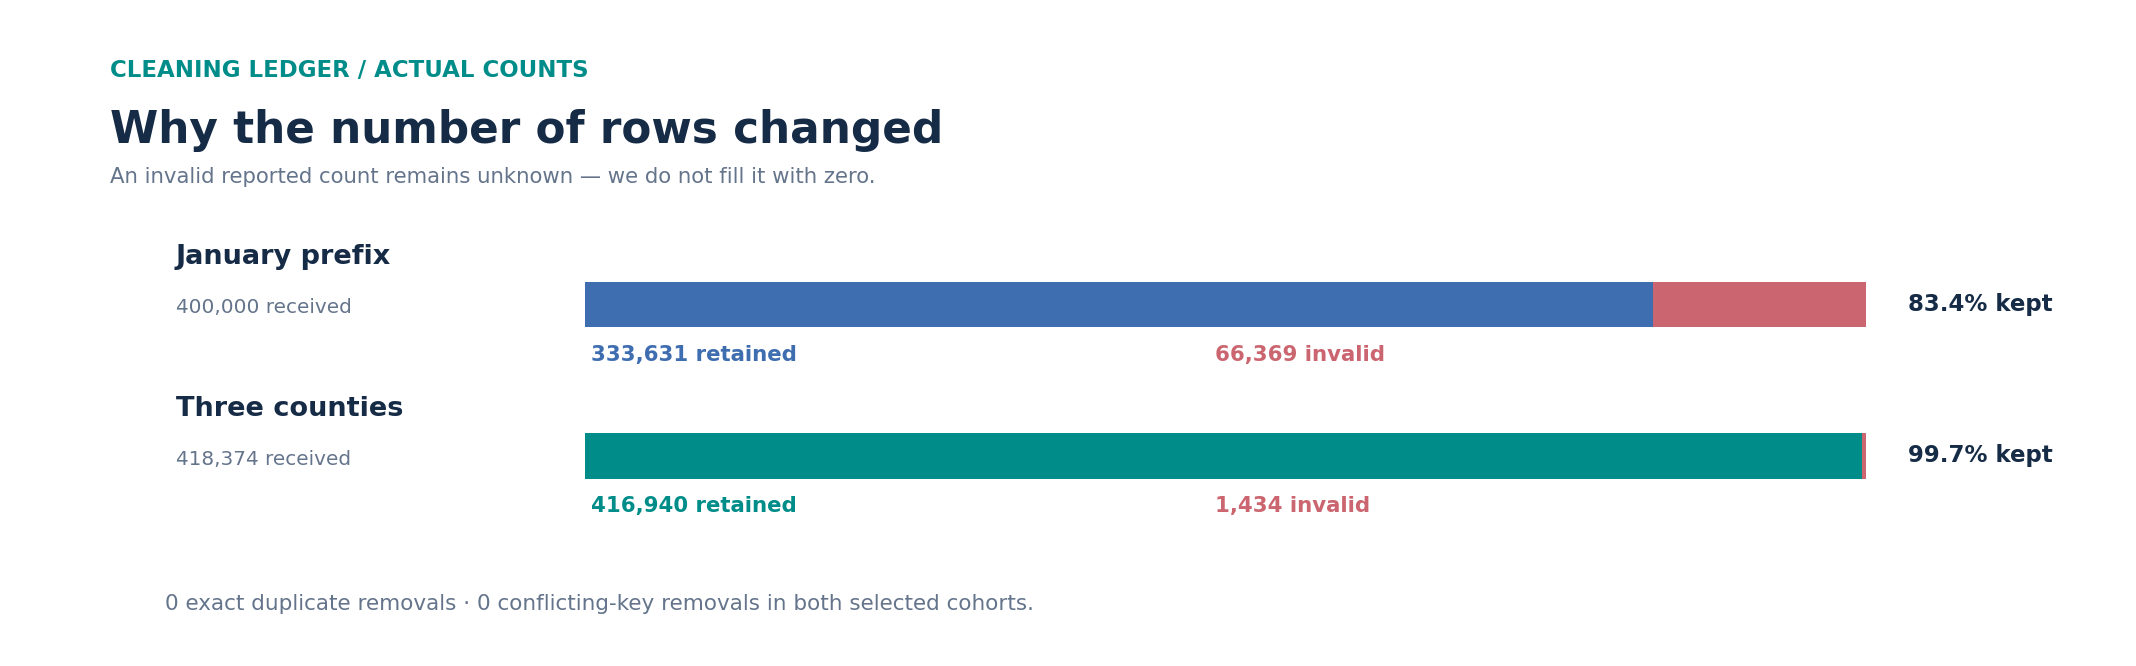

*Visual audit of reported rows retained and quarantined.*

### Duplicate Rows
Exact source duplicates are removed once. All variants of conflicting county-time keys are
quarantined; arbitrary first/mean values could manufacture an outcome. Reconciliation includes
invalids, removed exact duplicates, conflict rows and retained Silver observations.

**What / why:** Reconcile cleaning totals and verify unique retained county-time keys. Removing exact copies differs from resolving contradictory measurements.

**How:** clean first rejects invalid rows, removes exact valid source duplicates, then quarantines every distinct variant of conflicting keys with an anti-join. The accounting categories are disjoint.

**Implementation:** `src/gridrescue/pipeline.py: clean`.

In [13]:
# Read the measured cleaning ledger for this exact subset.
counts = audit['counts']
display(counts)
# Check that each original row contributes to exactly one cleaning outcome.
assert counts['raw'] == sum(counts[k] for k in ['invalid','exact_duplicates_removed','conflict_rows','silver'])
# Search for any repeated county-time key in Silver. One example would fail.
assert silver.groupBy('fips_code','timestamp').count().filter('count > 1').limit(1).count() == 0
print('Row reconciliation and clean-key uniqueness verified for this actual subset.')

# Run the same cleaning on the current CSV prefixes and compare with the verified ledger.
live_silver, live_quarantine, live_cleaning_counts = clean(raw) if MODE != 'memory' else (silver, quarantine, live_counts)
assert live_cleaning_counts == counts
assert live_quarantine.count() == counts['invalid'] + counts['conflict_rows']
# exceptAll compares complete rows and preserves multiplicity if a duplicate slips through.
clean_columns = silver.columns
assert live_silver.select(*clean_columns).exceptAll(silver).limit(1).count() == 0
assert live_silver.count() == silver.count()
if MODE != 'memory':
    live_silver.unpersist()
print('Live prefix CSV cleaning agrees with the ledger, quarantine count and all persisted clean rows.')


{'raw': 400000,
 'invalid': 66369,
 'exact_duplicates_removed': 0,
 'conflict_rows': 0,
 'silver': 333631}

Row reconciliation and clean-key uniqueness verified for this actual subset.


Live prefix CSV cleaning agrees with the ledger, quarantine count and all persisted clean rows.


#### Understanding the code — cleaning

The ledger separates invalid reports, exact duplicates, conflicting keys and usable rows. Spark `groupBy(*KEY).count()` groups rows by county and time, then `filter()` keeps counts greater than one. **TA question:** What happens if we keep one arbitrary conflicting row? **Answer:** The chosen count could alter neighboring lags and labels, so both variants go to quarantine.

### Inspect the implemented cleaning rules

**What/why:** expose the actual shared implementation instead of hiding decisions in a function call. **How:** display its source without rerunning it. **Where:** src/gridrescue/pipeline.py: clean.

In [14]:
display(Code(inspect.getsource(clean),language='python'))

def clean(raw):
    """Return clean unique reports, quarantined rows and a reconciliation ledger."""
    # Safe parsing returns null for a bad token so the report can be quarantined.
    parsed=(raw.withColumn('timestamp',F.expr("try_to_timestamp(run_start_time, 'yyyy-MM-dd HH:mm:ss')"))
            .withColumn('_count',F.expr('try_cast(customers_out as bigint)')))
    conditions=[(~F.col('fips_code').rlike('^[0-9]{5}$'),'invalid_fips'),
                (F.col('timestamp').isNull() | (~F.col('run_start_time').rlike(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$')),'invalid_timestamp'),
                (F.col('timestamp').isNotNull() & (F.unix_timestamp('timestamp') % 900 != 0),'off_grid_timestamp'),
                ((~F.col('customers_out').rlike('^[0-9]+$')) | F.col('_count').isNull(),'invalid_count'),
                (F.col('county').isNull() | F.col('state').isNull(),'missing_geography')]
    reasons=[F.when(F.coalesce(cond,F.lit(True)),F.lit(reason)) for cond,reason in conditions]
    parsed=parsed.withColumn('reason',F.concat_ws('|',*reasons)).cache()
    invalid=parsed.filter("reason != ''")
    valid=parsed.filter("reason = ''").drop('reason').cache()
    distinct=valid.dropDuplicates(SOURCE).cache()
    # Each remaining repeated key contains multiple distinct source rows.
    conflicts=distinct.groupBy(*KEY).count().filter('count > 1').select(*KEY)
    conflict_rows=distinct.join(conflicts,KEY,'inner').cache()
    # A left anti join keeps only source rows without a matching conflict key.
    silver=(distinct.join(conflicts,KEY,'left_anti').drop('customers_out')
            .withColumnRenamed('_count','customers_out').cache())
    stats=dict(raw=raw.count(),invalid=invalid.count(),exact_duplicates_removed=valid.count()-distinct.count(),conflict_rows=conflict_rows.count(),silver=silver.count())
    assert stats['raw']==sum(stats[k] for k in ['invalid','exact_duplicates_removed','conflict_rows','silver'])
    rejected=invalid.unionByName(conflict_rows.withColumn('reason',F.lit('conflicting_key')))
    # The caller can persist outputs; retain only useful caches.
    parsed.unpersist(); valid.unpersist(); distinct.unpersist()
    return silver,rejected,stats

### Outlier Detection
Tukey's IQR rule flags candidates, not errors. Large disasters can produce real extreme counts.
Quantiles use Spark approximate quantiles with documented relative rank tolerance 0.001.

**What / why:** Compute a Tukey upper fence and inspect actual extreme reports. A rare severe outage can be valid; statistical rarity alone is insufficient for removal.

**How:** IQR=Q3−Q1 and fence=Q3+1.5×IQR. Spark approximate quantiles have relative rank error 0.001. Plot input is bounded to 1,000 actual rows.

**Implementation:** `Spark approxQuantile; audit outlier policy`.

{'Q1': 2.0,
 'median': 5.0,
 'Q3': 41.0,
 'upper_fence': 99.5,
 'n': 333631,
 'maximum': 22952,
 'above_IQR_fence': 51859}

+---------+-------------------+----------+-------+-------------------+-------------+
|fips_code|timestamp          |county    |state  |run_start_time     |customers_out|
+---------+-------------------+----------+-------+-------------------+-------------+
|18141    |2021-01-02 17:15:00|St. Joseph|Indiana|2021-01-02 17:15:00|22952        |
|18141    |2021-01-02 17:00:00|St. Joseph|Indiana|2021-01-02 17:00:00|22938        |
|18141    |2021-01-02 17:30:00|St. Joseph|Indiana|2021-01-02 17:30:00|22898        |
|18141    |2021-01-02 16:45:00|St. Joseph|Indiana|2021-01-02 16:45:00|22877        |
|18141    |2021-01-02 16:30:00|St. Joseph|Indiana|2021-01-02 16:30:00|22855        |
|18141    |2021-01-02 16:15:00|St. Joseph|Indiana|2021-01-02 16:15:00|22827        |
|18141    |2021-01-02 16:00:00|St. Joseph|Indiana|2021-01-02 16:00:00|22729        |
|18141    |2021-01-02 15:45:00|St. Joseph|Indiana|2021-01-02 15:45:00|22573        |
|18141    |2021-01-02 15:15:00|St. Joseph|Indiana|2021-01-02 15:1

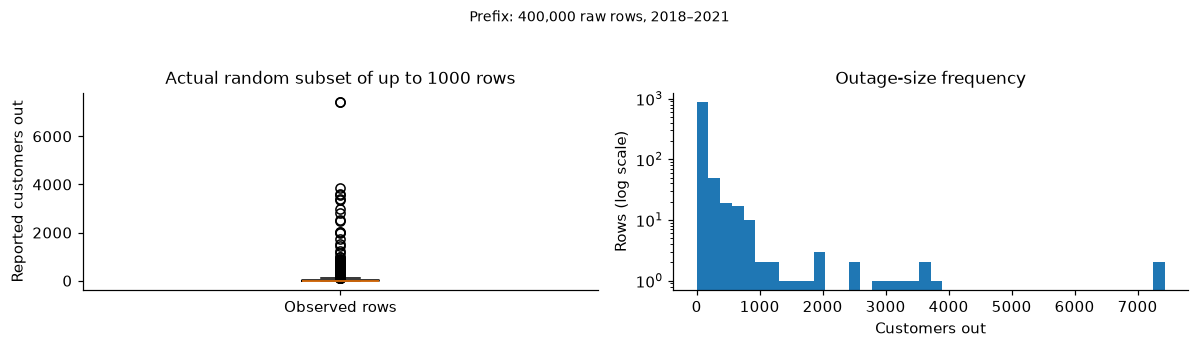

Measured subset: 51859 / 333631 values exceed the IQR fence 99.5; flags alone do not prove error.


In [15]:
# Find the first, second and third quartiles on the clean outage counts.
q1,q2,q3 = silver.approxQuantile('customers_out',[0.25,0.5,0.75],0.001)
# The IQR is Q3 minus Q1. The upper fence adds 1.5 times that spread to Q3.
fence = q3 + 1.5*(q3-q1)
# Count observations and flag values above the fence without dropping them.
stats = silver.agg(F.count('*').alias('n'), F.max('customers_out').alias('maximum'),
         F.sum((F.col('customers_out')>fence).cast('long')).alias('above_IQR_fence')).first().asDict()
display({'Q1':q1,'median':q2,'Q3':q3,'upper_fence':fence,**stats})
silver.orderBy(F.desc('customers_out')).show(10, truncate=False)
plot_rows = silver.orderBy(F.rand(17)).limit(1000).select('customers_out').toPandas()
fig,axes=plt.subplots(1,2,figsize=(11,3))
axes[0].boxplot(plot_rows['customers_out']); axes[0].set_title('Actual random subset of up to 1000 rows')
axes[1].hist(plot_rows['customers_out'],bins=40); axes[1].set_yscale('log')
axes[0].set_ylabel('Reported customers out'); axes[0].set_xticks([1],['Observed rows']); axes[1].set_title('Outage-size frequency'); axes[1].set_xlabel('Customers out'); axes[1].set_ylabel('Rows (log scale)'); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
print(f"Measured subset: {stats['above_IQR_fence']} / {stats['n']} values exceed the IQR fence {fence:g}; flags alone do not prove error.")

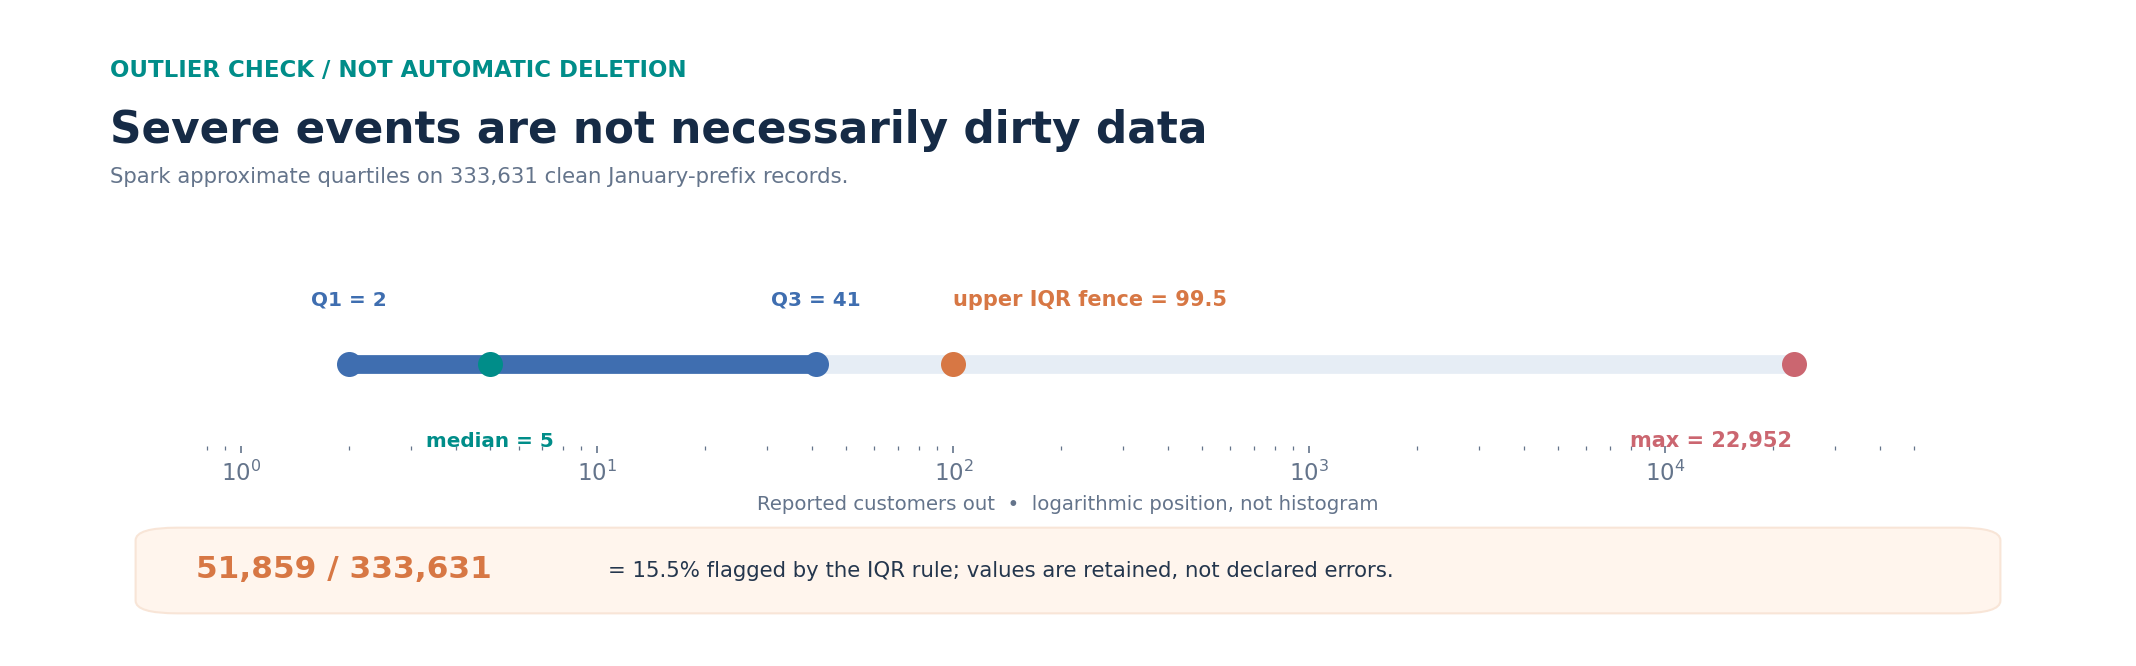

*Logarithmic marker illustration using approximate quartiles, fence and true maximum.*

### Outlier Treatment Techniques
Keep plausible nonnegative integral reports. Capping/removal could suppress exactly the escalation
events of interest; log1p is shown as a reversible visualization transform only. No learned cap is
fitted on validation or 2022. Invalid tokens are handled separately by quarantine.

**What / why:** Compare keeping, capping, removing and visually transforming extremes. Capping or deleting severe observations could erase the phenomenon being studied.

**How:** log1p changes the display only; original nonnegative integral values stay in Silver and X.

**Implementation:** `NumPy log1p in the cell; pipeline.clean does not clip valid counts`.

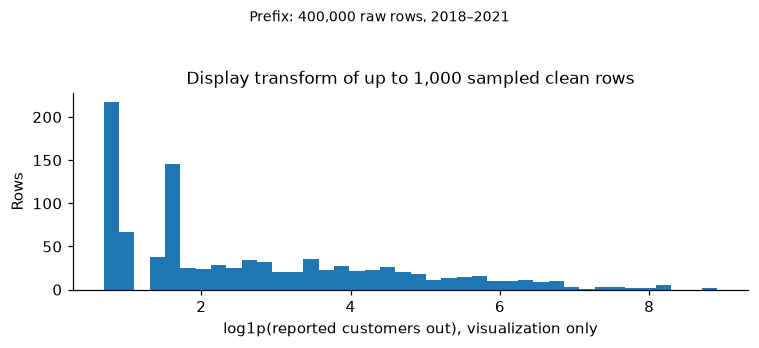

Treatment comparison: keep = preserves reported severity; cap/remove = loses extremes; log1p = reduces display skew. Raw counts retained.


In [16]:
import numpy as np
plt.figure(figsize=(7,3)); plt.hist(np.log1p(plot_rows['customers_out']),bins=40)
plt.title('Display transform of up to 1,000 sampled clean rows'); plt.xlabel('log1p(reported customers out), visualization only'); plt.ylabel('Rows'); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
print('Treatment comparison: keep = preserves reported severity; cap/remove = loses extremes; log1p = reduces display skew. Raw counts retained.')

#### Understanding the code — IQR and outliers

`approxQuantile()` estimates Q1 and Q3. IQR measures the middle half of the distribution and the fence identifies unusually high observations. **TA question:** Why keep them? **Answer:** A credible large outage is part of the population we want to study. Clipping would change its features and possibly its label.

<a id="task1-eda"></a>
## 03 Exploratory Data Analysis
### 1. Univariate Analysis
Charts use small aggregates or bounded samples; the full dataset is never collected into pandas.

**What / why:** Plot one-variable distributions and UTC observation coverage. Describe skew and reporting patterns before comparing variables.

**How:** Only small grouped results and bounded observations go to the plotting library; row counts describe reporting, not unique customers.

**Implementation:** `Spark groupBy and Matplotlib`.

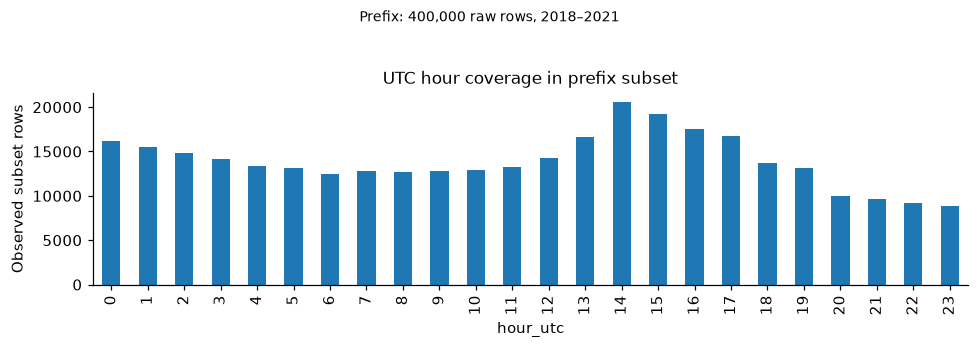

Most represented UTC hour in this subset: 14, 20568 rows. Prefix selection prevents seasonal inference.


In [17]:
# Reduce all prefix rows to one count and mean per observed UTC hour.
hourly = gold.groupBy('hour_utc').agg(F.count('*').alias('observed_rows'),F.avg('customers_out_t').alias('mean_customers_out')).orderBy('hour_utc').toPandas()
hourly.plot(x='hour_utc',y='observed_rows',kind='bar',legend=False,figsize=(9,3))
plt.ylabel('Observed subset rows'); plt.title('UTC hour coverage in prefix subset'); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
peak = hourly.loc[hourly['observed_rows'].idxmax()]
print(f"Most represented UTC hour in this subset: {int(peak['hour_utc'])}, {int(peak['observed_rows'])} rows. Prefix selection prevents seasonal inference.")

> **TA takeaway — coverage vs. severity**  
> The UTC-hour bar chart measures *row frequency in this selected prefix*, not unique outages or hourly causal effects.

### Extra univariate audit — categorical frequency and skewness

The final rubric also asks for important categorical count plots and numerical distributions. **Rows measure *reporting coverage***, not unique customers. A bounded sample is used for numerical plotting; Spark computes aggregate frequencies.

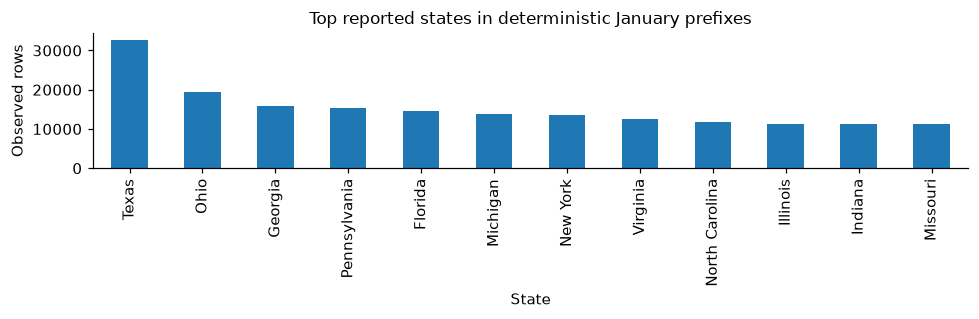

Outage-count skewness in prefix cohort: 16.363443119638855
These counts cannot be interpreted as independent people or events.


summary                count       mean      stddev         min   25%    50%  \
customers_out_t       333631    117.216     591.136       1.000 2.000  5.000   
lag_15m               308434    124.125     610.176       1.000 2.000  6.000   
lag_60m               257179    141.471     654.247       1.000 2.000  8.000   
delta_60m             257179     -3.617     329.379 -19,102.000 0.000  0.000   
rolling_mean_60m      333631    118.250     573.963       1.000 2.000  6.333   
rolling_variance_60m  333631 19,791.120 452,262.309       0.000 0.000  0.000   
history_slots_60m     333631      4.376       1.211       1.000 4.000  5.000   
hour_utc              333631     11.081       6.644       0.000 5.000 12.000   
weekday_utc           333631      4.191       1.644       2.000 3.000  4.000   
month_utc             333631      1.000       0.000       1.000 1.000  1.000   

summary                 75%            max  
customers_out_t      41.000     22,952.000  
lag_15m              45.000     22,952.000  
lag_60m              56.000     22,877.000  
delta_60m             0.000     16,138.000  
rolling_mean_60m     44.800     22,904.000  
rolling_variance_60m  6.640 54,883,376.960  
history_slots_60m     5.000          5.000  
hour_utc             16.000         23.000  
weekday_utc           6.000          7.000  
month_utc             1.000          1.000

*Scope: Ten most frequently reported counties in the January prefixes; up to 10 displayed rows.*

fips_code       county  count
0     06037  Los Angeles    657
1     48201       Harris    656
2     12086   Miami-Dade    655
3     26125      Oakland    651
4     26163        Wayne    651
5     17031         Cook    643
6     01073    Jefferson    641
7     48113       Dallas    635
8     34013        Essex    631
9     12011      Broward    630

The count for each lag shows its observed support. A constant month in the prefixes cannot establish seasonality.


In [18]:
# A count plot of observed state records, computed in Spark.
state_frequencies = (silver.groupBy("state")
                     .agg(F.count("*").alias("observed_rows"))
                     .orderBy(F.desc("observed_rows")))
plot_states = state_frequencies.limit(12).toPandas()
ax = plot_states.plot.bar(x="state", y="observed_rows", legend=False, figsize=(9, 3))
ax.set(xlabel="State", ylabel="Observed rows", title="Top reported states in deterministic January prefixes")
plt.tight_layout(); plt.show()

# Skewness is descriptive, not an instruction to delete valid extremes.
skew = silver.select(F.skewness("customers_out").alias("skewness")).first()[0]
print("Outage-count skewness in prefix cohort:", skew)
print("These counts cannot be interpreted as independent people or events.")

# Summarize all numeric Gold predictors in Spark before collecting the eight statistic rows.
numeric_summary = gold.select(*PREDICTORS).summary(
    'count', 'mean', 'stddev', 'min', '25%', '50%', '75%', 'max'
).toPandas().set_index('summary').T
# summary() returns strings so the same output column can hold both counts and averages.
display(numeric_summary.apply(pd.to_numeric))
# Preserve the FIPS/name relationship while comparing the most frequently reported counties.
county_counts = (silver.groupBy('fips_code', 'county').count()
                 .orderBy(F.desc('count'), 'fips_code'))
show_table(county_counts, 10, scope='Ten most frequently reported counties in the January prefixes')
print('The count for each lag shows its observed support. A constant month in the prefixes cannot establish seasonality.')


### 2. Feature vs. Target Analysis
Development-only target associations are descriptive, not model accuracy or operational validation.
Strict 12-slot completeness selects persistent observed outages and may bias both classes.

**What / why:** Compare past/current features across complete-case escalation classes. Look for descriptive associations while exposing the selection rule.

**How:** Group means and class counts use eligible anchors only. The current count also enters the target threshold, so this relationship is partly definitional.

**Implementation:** `pipeline.audit_labels; Spark grouped means`.

*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 2 displayed rows.*

candidate_y    rows  mean_current  mean_past_change
0            0  150642       186.237             0.452
1            1   12744       231.175           -19.562

candidate_y           No escalation  Escalation
customers_out_t             186.237     231.175
lag_15m                     190.218     244.510
lag_60m                     199.544     270.601
delta_60m                     0.452     -19.562
rolling_mean_60m            185.499     238.718
rolling_variance_60m     30,430.113  48,161.754
history_slots_60m             4.672       4.559
hour_utc                     10.509      10.314
weekday_utc                   4.291       4.137
month_utc                     1.000       1.000
lag_15m_missing               0.039       0.054
lag_60m_missing               0.122       0.160
delta_60m_missing             0.122       0.160

Table: observed feature means by complete-case label; calendar means are descriptive numeric baseline codes.


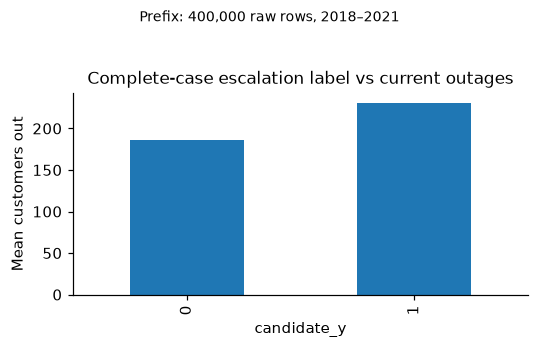

Class-conditional differences above are measured associations among complete windows; no causal or predictive claim follows.


**Interpretation:** candidate 0: 150,642 anchors, mean current count 186.2; candidate 1: 12,744 anchors, mean current count 231.2. These overlapping retrospective windows are not independent events.

In [19]:
# Use only complete eligible labels for this descriptive comparison.
target_inputs=eligible
for column in ['lag_15m','lag_60m','delta_60m']:
    # Use only complete eligible labels for this descriptive comparison.
    target_inputs=target_inputs.withColumn(column+'_missing',F.col(column).isNull().cast('double'))
target_names=PREDICTORS+[c+'_missing' for c in ['lag_15m','lag_60m','delta_60m']]
# Group by binary outcome and calculate means within each class.
target_groups = target_inputs.groupBy('candidate_y').agg(F.count('*').alias('rows'),
    F.avg('customers_out_t').alias('mean_current'),F.avg('delta_60m').alias('mean_past_change'),*[F.avg(c).alias('avg_'+c) for c in target_names]).orderBy('candidate_y')
show_table(target_groups.select('candidate_y','rows','mean_current','mean_past_change'),2)
# Move the two aggregated class rows to pandas for plotting.
target_plot = target_groups.toPandas()
display(target_plot.set_index('candidate_y')[['avg_'+c for c in target_names]].rename(index={0:'No escalation',1:'Escalation'}).T.rename(index=lambda name:name.removeprefix('avg_')))
print('Table: observed feature means by complete-case label; calendar means are descriptive numeric baseline codes.')
if not target_plot.empty:
    # Move the two aggregated class rows to pandas for plotting.
    target_plot.plot(x='candidate_y',y='mean_current',kind='bar',legend=False,figsize=(5,3))
    plt.title('Complete-case escalation label vs current outages'); plt.ylabel('Mean customers out'); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
print('Class-conditional differences above are measured associations among complete windows; no causal or predictive claim follows.')
display(Markdown('**Interpretation:** ' + '; '.join(
    f"candidate {int(r.candidate_y)}: {int(r.rows):,} anchors, mean current count {r.mean_current:,.1f}"
    for r in target_groups.collect()) + '. These overlapping retrospective windows are not independent events.'))

> **TA takeaway — target association**  
> Mean current count is 186.2 for the no-escalation class and 231.2 for the escalation class in the *complete-case prefix*. Association does not prove predictive accuracy.

### 3. Feature-to-Feature Analysis

**What / why:** Plot current counts, exact past lags, past change and variability. Related features can encode overlapping information.

**How:** A seeded 1,000-row display preserves raw pairs. Missing pairs are omitted from each scatter plot, not zero-filled.

**Implementation:** `pipeline.features and bounded scatter plots`.

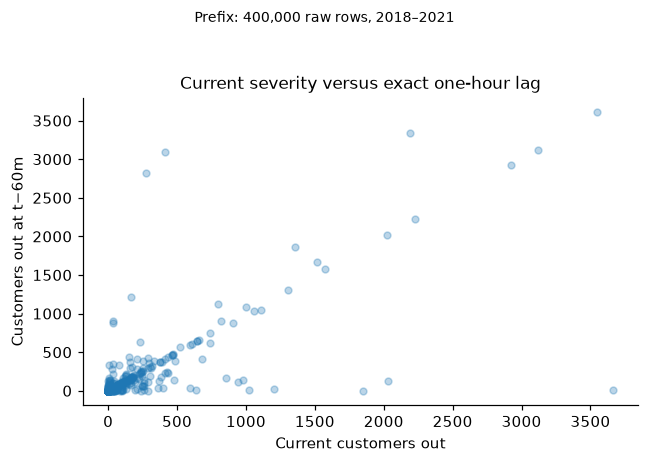

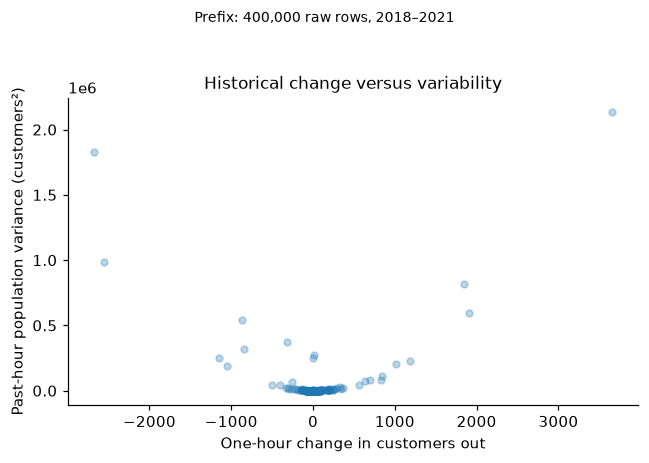

Current and lag values describe persistence; delta and variance can overlap. Missing exact lags remain absent, so plotted pairs exclude those gaps.


In [20]:
# Collect a bounded seeded sample with four numeric columns for scatterplots.
relationships = gold.orderBy(F.rand(17)).limit(1000).select('customers_out_t','lag_60m','delta_60m','rolling_variance_60m').toPandas()
relationships.plot.scatter(x='customers_out_t',y='lag_60m',alpha=0.3,figsize=(6,4)); plt.title('Current severity versus exact one-hour lag'); plt.xlabel('Current customers out'); plt.ylabel('Customers out at t−60m'); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
relationships.plot.scatter(x='delta_60m',y='rolling_variance_60m',alpha=0.3,figsize=(6,4)); plt.title('Historical change versus variability'); plt.xlabel('One-hour change in customers out'); plt.ylabel('Past-hour population variance (customers²)'); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
print('Current and lag values describe persistence; delta and variance can overlap. Missing exact lags remain absent, so plotted pairs exclude those gaps.')

> **TA takeaway — relationships**  
> Historical lags and rolling summaries share source observations, so correlation can reflect engineered overlap; sampled scatterplots also hide missing-lag pairs.

### 4. Correlation Analysis

**What / why:** Calculate a Pearson correlation matrix for numeric feature pairs. Quantify linear association without treating geography IDs as magnitudes.

**How:** pandas computes only on the already bounded plotting sample. Pairwise missingness changes the rows used for each coefficient.

**Implementation:** `relationships sample from the preceding cell`.

customers_out_t  lag_60m  delta_60m  \
customers_out_t                 1.000    0.745      0.333   
lag_60m                         0.745    1.000     -0.381   
delta_60m                       0.333   -0.381      1.000   
rolling_variance_60m            0.420    0.336      0.107   

                      rolling_variance_60m  
customers_out_t                      0.420  
lag_60m                              0.336  
delta_60m                            0.107  
rolling_variance_60m                 1.000

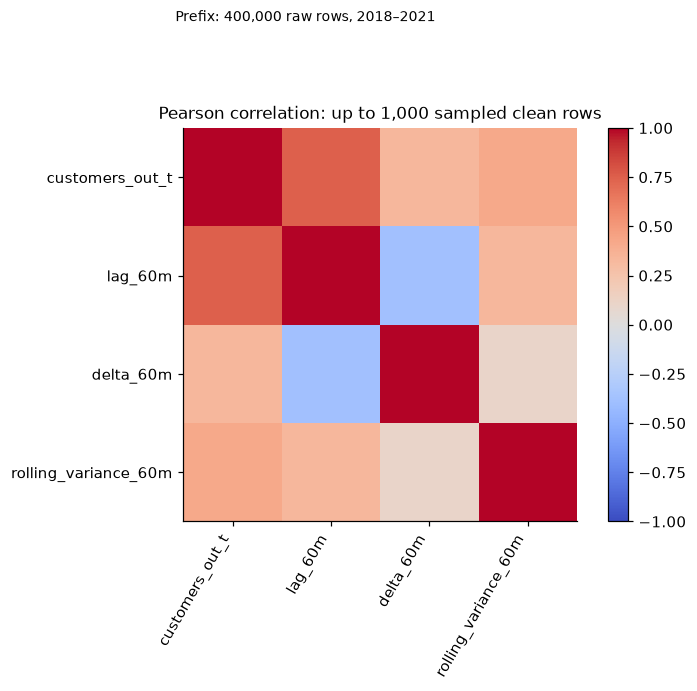

Sign gives linear direction; magnitude gives linear strength. Pairwise missingness and skew can distort correlations; FIPS and future outcomes are excluded.


**Interpretation:** current count versus exact 60-minute lag has sampled Pearson r=0.745. Positive values indicate historical persistence; this sample association is neither a causal effect nor model performance.

In [21]:
# Calculate pairwise Pearson r using the sampled rows available for each pair.
corr = relationships.corr(numeric_only=True)
display(corr)
# Use the full -1 to +1 color scale so the colors have a consistent meaning.
fig,ax=plt.subplots(figsize=(7.5,6)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=60,ha='right'); ax.set_yticks(range(len(corr)),corr.index)
fig.colorbar(im,ax=ax); plt.title('Pearson correlation: up to 1,000 sampled clean rows'); plt.tight_layout(rect=(0,0,1,.92)); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
print('Sign gives linear direction; magnitude gives linear strength. Pairwise missingness and skew can distort correlations; FIPS and future outcomes are excluded.')
r=corr.loc['customers_out_t','lag_60m']
display(Markdown(f'**Interpretation:** current count versus exact 60-minute lag has sampled Pearson r={r:.3f}. Positive values indicate historical persistence; this sample association is neither a causal effect nor model performance.'))

> **TA takeaway — heatmap**  
> Read sign and magnitude; Pearson measures only linear association. The matrix is computed from at most 1,000 seeded prefix rows, not all counties/months.

<a id="task1-vif"></a>
### Multivariate check — redundancy, multicollinearity, and unusual combinations

The exact 60-minute change is the current count minus the exact one-hour lag, so these three variables are algebraically dependent when both values exist. This is a **real interpretation issue**, not a reason to remove the feature silently. We illustrate a VIF-style linear redundancy audit on bounded **development-only** complete observations. VIF may become infinite for exact linear relationships; it is not a model performance metric. Because the subset is deterministic and conditional, do not generalize these VIF values nationally.

In [22]:
from sklearn.linear_model import LinearRegression
vif_columns = ["customers_out_t", "lag_60m", "delta_60m", "rolling_mean_60m", "rolling_variance_60m"]
# Keep complete rows for all five variables, then bound the local regression sample.
vif_sample = (gold.select(*vif_columns)
              .dropna(subset=vif_columns)
              .orderBy(F.rand(seed=41)).limit(3000).toPandas())

vif_rows = []
if len(vif_sample) < 30:
    print("UNVERIFIED: too few complete rows for an informative VIF audit.")
else:
    # Use each predictor as a temporary regression outcome and the rest as inputs.
    for feature_name in vif_columns:
        target = vif_sample[feature_name].to_numpy(dtype=float)
        peers = vif_sample.drop(columns=feature_name).to_numpy(dtype=float)
        if np.isclose(target.var(), 0):
            vif = float("nan")  # A constant predictor has no meaningful VIF.
        else:
            # Fit on the same sample because this calculation measures predictor redundancy.
            r2 = LinearRegression().fit(peers, target).score(peers, target)
            vif = float("inf") if r2 >= 1 - 1e-10 else 1.0 / max(1e-12, 1-r2)
        vif_rows.append({"feature": feature_name, "VIF_style": vif})
    display(pd.DataFrame(vif_rows))
    identity_error = np.abs(vif_sample["customers_out_t"] - vif_sample["lag_60m"] - vif_sample["delta_60m"]).max()
    assert identity_error < 1e-9, "Unexpected delta identity mismatch"
    print("Max absolute deviation from delta=current−lag60:", identity_error)

# Count impossible history sizes and negative variances over the Spark frame.
quality_audit = gold.agg(
    F.sum((~F.col("history_slots_60m").between(1,5)).cast("long")).alias("invalid_history_slot_count"),
    F.sum((F.col("rolling_variance_60m") < 0).cast("long")).alias("negative_rolling_variance_count")
).first().asDict()
display(quality_audit)
assert quality_audit["invalid_history_slot_count"] == 0
assert quality_audit["negative_rolling_variance_count"] == 0
print("Rare geography categories and sparse-reporting periods may generalize poorly; countrywide representation is not established.")

feature  VIF_style
0       customers_out_t        inf
1               lag_60m        inf
2             delta_60m        inf
3      rolling_mean_60m     58.579
4  rolling_variance_60m      1.184

Max absolute deviation from delta=current−lag60: 0


{'invalid_history_slot_count': 0, 'negative_rolling_variance_count': 0}

Rare geography categories and sparse-reporting periods may generalize poorly; countrywide representation is not established.


### 5. GroupBy / Statistical Summary Analysis

**What / why:** Compare observed rows and outage-size summaries by state. Separate reporting coverage from severity and avoid totals of repeated people.

**How:** groupBy partitions logical groups; agg reduces each group; orderBy selects compact chart summaries.

**Implementation:** `Spark groupBy/agg/orderBy`.

+--------------+------------+------------------+-----------------+
|state         |observations|mean_customers_out|max_customers_out|
+--------------+------------+------------------+-----------------+
|Texas         |32774       |102.47433941539025|6928             |
|Ohio          |19438       |142.49305484103303|10102            |
|Georgia       |15816       |35.762392513909965|2827             |
|Pennsylvania  |15454       |129.90358483240584|9451             |
|Florida       |14542       |65.27774721496355 |16142            |
|Michigan      |13799       |183.90238423074135|9035             |
|New York      |13501       |250.89985926968373|14966            |
|Virginia      |12572       |50.64643652561247 |6005             |
|North Carolina|11697       |75.66393092245875 |6039             |
|Illinois      |11362       |153.06336912515403|5834             |
|Indiana       |11352       |429.1223572938689 |22952            |
|Missouri      |11162       |192.80021501523024|8084          

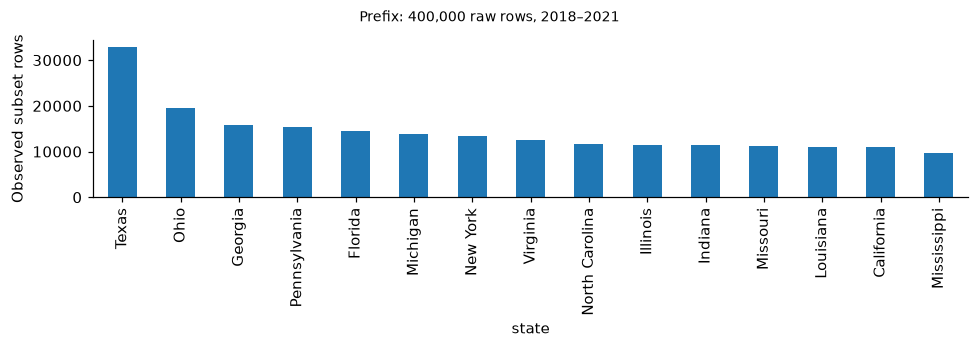

Most represented state in selected prefixes: Texas (32774 observations). Row totals measure observation coverage, not unique customers or total events.


In [23]:
# Collapse rows by state and compute report count, mean and maximum.
state_summary = silver.groupBy('state').agg(F.count('*').alias('observations'),F.avg('customers_out').alias('mean_customers_out'),
    F.max('customers_out').alias('max_customers_out')).orderBy(F.desc('observations'))
# Collapse rows by state and compute report count, mean and maximum.
state_summary.show(20,truncate=False)
# Collect only the largest 15 state groups for the chart.
state_plot = state_summary.limit(15).toPandas()
# Collect only the largest 15 state groups for the chart.
state_plot.plot(x='state',y='observations',kind='bar',legend=False,figsize=(9,3)); plt.ylabel('Observed subset rows'); plt.tight_layout(); plt.gcf().suptitle(SCOPE_LABEL,fontsize=9,y=1.04); plt.show()
top=state_summary.first()
print(f"Most represented state in selected prefixes: {top['state']} ({top['observations']} observations). Row totals measure observation coverage, not unique customers or total events.")

#### Understanding the code — Spark summaries

`groupBy()` divides observations into groups. `agg()` evaluates summaries such as counts and means, then `orderBy()` sorts the much smaller result. **TA question:** Is the report count a count of outages? **Answer:** It counts county-time rows. One event can contribute multiple reports.

### Full-year county context: severity and coverage

**What/why:** supplement January-only EDA with all development months for the fixed counties. **How:** aggregate the verified daily export into weighted monthly means and plot counts beside severity. **Where:** reports/dashboard/county/daily.csv; pipeline audit.

fips_code       county  year  observed_anchors  eligible  positive  \
0      06037  Los Angeles  2018             34254     32580     14063   
1      12086   Miami-Dade  2018             34673     33686     10863   
2      48201       Harris  2018             34644     33535     11209   
3      06037  Los Angeles  2019             34797     34339     15828   
4      12086   Miami-Dade  2019             34673     32854      9664   
5      48201       Harris  2019             34735     34156     11276   
6      06037  Los Angeles  2020             35011     34773     15799   
7      12086   Miami-Dade  2020             34925     34047     10338   
8      48201       Harris  2020             34905     33821     11947   
9      06037  Los Angeles  2021             34823     34476     14820   
10     12086   Miami-Dade  2021             34757     34057     10113   
11     48201       Harris  2021             34743     33916      8786   

    negative                first                 last  
0      18517  2018-01-01 00:00:00  2018-12-31 00:00:00  
1      22823  2018-01-01 00:00:00  2018-12-31 00:00:00  
2      22326  2018-01-01 00:00:00  2018-12-31 00:00:00  
3      18511  2019-01-01 00:00:00  2019-12-31 00:00:00  
4      23190  2019-01-01 00:00:00  2019-12-31 00:00:00  
5      22880  2019-01-01 00:00:00  2019-12-31 00:00:00  
6      18974  2020-01-01 00:00:00  2020-12-31 00:00:00  
7      23709  2020-01-01 00:00:00  2020-12-31 00:00:00  
8      21874  2020-01-01 00:00:00  2020-12-31 00:00:00  
9      19656  2021-01-01 00:00:00  2021-12-31 00:00:00  
10     23944  2021-01-01 00:00:00  2021-12-31 00:00:00  
11     25130  2021-01-01 00:00:00  2021-12-31 00:00:00

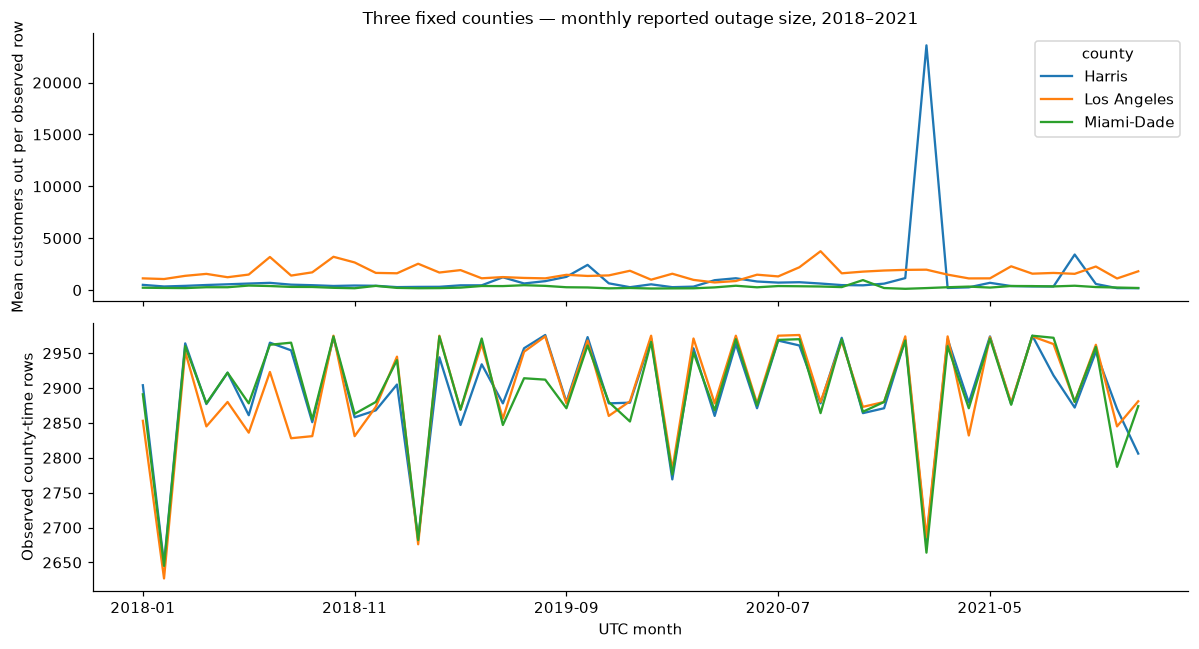

**Finding:** the highest observed county/month mean is 23,588.9 customers out in Harris during 2021-02. These are repeated reports, not unique people or a causal attribution. The lower panel shows the coverage supporting each mean; no missing observations became zeros.

**Reading monthly counts:** month length changes the number of possible rows; a lower monthly total alone does not prove a reporting failure. Calendar-based coverage qualification is reported separately.

In [24]:
# Read the verified one-row-per-county-year coverage summary.
coverage=pd.DataFrame(county_audit['coverage_by_county_year'])
display(coverage[['fips_code','county','year','observed_anchors','eligible','positive','negative','first','last']])
from gridrescue.dashboard_data import load_scope
county_daily,_=load_scope(ROOT,'county')  # Verified Spark daily aggregates, not raw data.
# Sum daily report counts and outage totals within each county and UTC month.
monthly=county_daily.assign(month=county_daily.date.dt.to_period('M').astype(str)).groupby(['month','county'])[['observations','sum_customer_observations']].sum().reset_index()
# Divide totals by reports. Averaging daily means would weight sparse days too heavily.
monthly['mean_customers_out']=monthly.sum_customer_observations/monthly.observations
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
monthly.pivot(index='month',columns='county',values='mean_customers_out').plot(ax=axes[0])
monthly.pivot(index='month',columns='county',values='observations').plot(ax=axes[1],legend=False)
axes[0].set(title='Three fixed counties — monthly reported outage size, 2018–2021',ylabel='Mean customers out per observed row')
axes[1].set(ylabel='Observed county-time rows',xlabel='UTC month')
plt.show()
peak=monthly.loc[monthly.mean_customers_out.idxmax()]
display(Markdown(f"**Finding:** the highest observed county/month mean is {peak.mean_customers_out:,.1f} customers out in {peak['county']} during {peak['month']}. These are repeated reports, not unique people or a causal attribution. The lower panel shows the coverage supporting each mean; no missing observations became zeros."))
display(Markdown('**Reading monthly counts:** month length changes the number of possible rows; a lower monthly total alone does not prove a reporting failure. Calendar-based coverage qualification is reported separately.'))

### Rare categories and coverage-selection risks

The national population can include counties with few reports; the three modeled counties were preselected for coverage and geography. We report *observed* county/year sample sizes rather than treating sparse regions as if they had zero outage. Low support is a warning for generalization, not evidence of low electricity-outage risk.

In [25]:
county_year_support = coverage[["fips_code", "county", "year", "observed_anchors", "eligible"]].copy()
county_year_support["eligible_fraction"] = (
    county_year_support["eligible"] / county_year_support["observed_anchors"].replace(0, np.nan)
)
display(county_year_support.sort_values("observed_anchors").head(12))
print("Least observed county/year:", county_year_support.loc[county_year_support["observed_anchors"].idxmin(), ["county", "year", "observed_anchors"]].to_dict())

fips_code       county  year  observed_anchors  eligible  eligible_fraction
0      06037  Los Angeles  2018             34254     32580              0.951
2      48201       Harris  2018             34644     33535              0.968
1      12086   Miami-Dade  2018             34673     33686              0.972
4      12086   Miami-Dade  2019             34673     32854              0.948
5      48201       Harris  2019             34735     34156              0.983
11     48201       Harris  2021             34743     33916              0.976
10     12086   Miami-Dade  2021             34757     34057              0.980
3      06037  Los Angeles  2019             34797     34339              0.987
9      06037  Los Angeles  2021             34823     34476              0.990
8      48201       Harris  2020             34905     33821              0.969
7      12086   Miami-Dade  2020             34925     34047              0.975
6      06037  Los Angeles  2020             35011     34773              0.993

Least observed county/year: {'county': 'Los Angeles', 'year': 2018, 'observed_anchors': 34254}


<a id="task1-three-findings"></a>
### Three EDA findings — generated from real executed evidence

The text below is populated from the actual Spark aggregates and county audit when this notebook runs. Each finding separates observed facts from interpretation, and should be copied into the final report only after a fresh execution.

In [26]:
# Use the observed outage values for the prefix mean and median.
prefix_mean = silver.agg(F.avg("customers_out")).first()[0]
prefix_median = q2
# Use the separate full-year county audit for the eligibility fraction.
county_total = int(county_audit["counts"]["silver"])
county_eligible = sum(int(x["eligible"]) for x in county_audit["coverage_by_county_year"])
# Find the county/month with the highest observed monthly mean.
peak_month = monthly.loc[monthly["mean_customers_out"].idxmax()]

finding_one = (f"**Finding 1 — skew and extremes:** Mean {prefix_mean:,.2f} versus median {prefix_median:,.2f} "
               f"reported customers out in the January prefixes; {stats['above_IQR_fence']:,} of {stats['n']:,} "
               f"clean observations exceed the IQR upper fence ({fence:,.1f}). We retain plausible high values.")
finding_two = (f"**Finding 2 — label eligibility / selection:** {county_eligible:,} eligible observed anchors "
               f"from {county_total:,} clean three-county development observations "
               f"({county_eligible / county_total:.1%}). This is conditional reporting coverage, not national prevalence.")
finding_three = (f"**Finding 3 — county/month variation:** Peak observed monthly mean was "
                 f"{peak_month['mean_customers_out']:,.1f} in {peak_month['county']} during {peak_month['month']}. "
                 "Interpret alongside observed-row counts; this is not causal evidence.")
for item in [finding_one, finding_two, finding_three]:
    display(Markdown(item))
assert 0 < county_eligible <= county_total
print("Caution: EDA comparisons are descriptive and overlapping anchors are not independent events.")

**Finding 1 — skew and extremes:** Mean 117.22 versus median 5.00 reported customers out in the January prefixes; 51,859 of 333,631 clean observations exceed the IQR upper fence (99.5). We retain plausible high values.

**Finding 2 — label eligibility / selection:** 406,240 eligible observed anchors from 416,940 clean three-county development observations (97.4%). This is conditional reporting coverage, not national prevalence.

**Finding 3 — county/month variation:** Peak observed monthly mean was 23,588.9 in Harris during 2021-02. Interpret alongside observed-row counts; this is not causal evidence.

Caution: EDA comparisons are descriptive and overlapping anchors are not independent events.


<a id="task1-findings"></a>
## 04 Findings and Limitations
Explain the measured outputs above before making claims. Prefix scope, sparse reporting,
repeated customers across intervals and candidate-label selection are material limitations.

**What / why:** Summarize verified counts, decisions and limitations. A defensible conclusion must say exactly which population was processed.

**How:** Reuse measured audit outputs rather than recomputing or inventing full-source results. Release the Spark session after the final checks.

**Implementation:** `reports/windows/{sample,county}/audit.json and scope ledger`.

In [27]:
print('Measured raw -> invalid / exact duplicates / conflict variants -> silver:', counts)
print('No absent rows were filled; plausible extremes retained. Exact-time features are in Gold.')
print('Three-county experiment approved; these prefix associations are not model performance or national evidence.')
county_audit=county_scope_audit
display(Markdown(f"**Scope comparison:** prefixes retain {counts['silver']:,} of {counts['raw']:,} rows. The three fixed counties retain {county_audit['counts']['silver']:,} of {county_audit['counts']['raw']:,} rows over all development years. Their much higher reporting coverage means neither scope estimates population-wide eligibility."))
print('National full-source deduplication, Gold features and labels have not been computed. This is scoped EDA, not a completed national pipeline.')
raw.unpersist()
spark.stop()

Measured raw -> invalid / exact duplicates / conflict variants -> silver: {'raw': 400000, 'invalid': 66369, 'exact_duplicates_removed': 0, 'conflict_rows': 0, 'silver': 333631}
No absent rows were filled; plausible extremes retained. Exact-time features are in Gold.
Three-county experiment approved; these prefix associations are not model performance or national evidence.


**Scope comparison:** prefixes retain 333,631 of 400,000 rows. The three fixed counties retain 416,940 of 418,374 rows over all development years. Their much higher reporting coverage means neither scope estimates population-wide eligibility.

National full-source deduplication, Gold features and labels have not been computed. This is scoped EDA, not a completed national pipeline.
